# Portfolio opdracht 1, Voorspel herseninfarct

**Teamnaam** ML Monsters

Jay Mancham:
- 25084240
- Kaggle account: jaimancham  - Jay

Emirhan Aydin:
- 25099590
- Kaggle account: emirkay  - Emirhan Aydin

# 1. Exploratieve data-analyse (opdracht 1)

## 1.1 Imports
Alle packages die we in dit notebook gebruiken laden we hier in één keer in.

In [1]:
%pip install imbalanced-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
# standaardbibliotheek
import time

# data en visualisatie
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

# scikit-learn
from sklearn.base import clone
from sklearn.ensemble import (GradientBoostingClassifier,
                              RandomForestClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             f1_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)

## 1.2 Voldoet de data aan de minimale vereisten voor scikit-learn?

Missende waarden :
Er ontbreken geen waarden. Dat hebben we gecontroleerd met de methode count_missing() in
paragraaf 1.4. Die geeft voor iedere kolom 0. Ook zie je in de basisstatistieken
(kolom count) dat iedere kolom 33.550 ingevulde waarden heeft, precies het
aantal rijen.

Datatypes :
Alle kolommen zijn numeriek. De dataset bevat drie datatypes: int64 (hele getallen),
float64 (kommagetallen) en bool (True/False). Scikit-learn ziet True als 1 en
False als 0, dus ook de bool-kolommen zijn bruikbaar. Voor de duidelijkheid
zetten we ze in de klasse StrokeData (paragraaf 1.4) om naar 0 en 1.

Dummy-kolommen :
Oorspronkelijk bevatte de dataset categorische kolommen met tekst, zoals gender,
work_type en smoking_status. Scikit-learn kan alleen met getallen rekenen, daarom
zijn deze kolommen al omgezet naar dummy-kolommen (one-hot encoding). Voor elke
categorie is een aparte kolom gemaakt met True of False.
Als we de categorieën gewoon zouden omzetten naar getallen (bijvoorbeeld Female = 0,
Male = 1, Other = 2), dan zou het model denken dat er een volgorde en afstand tussen
de categorieën zit. 

Afhankelijke variabele :
De afhankelijke variabele is de kolom stroke: 1 betekent dat iemand een
herseninfarct heeft gehad, 0 betekent van niet. Alle andere kolommen zijn de
onafhankelijke variabelen. We hebben dus te maken met een binair classificatieprobleem.

Ongebalanceerde data :
De dataset is ongebalanceerd: slechts 517 van de 33.550 patiënten (± 1,5%) heeft een
herseninfarct gehad. Dat komt doordat een herseninfarct in de algemene
bevolking relatief weinig voorkomt. In paragraaf 3.1 gaan we hier verder
op in.

## 1.3 Beschrijving van de kolommen
| Kolom | Betekenis | Waarden |
|---|---|---|
| `id` | Uniek nummer per patiënt. Zegt niets over de gezondheid, wordt niet gebruikt om te voorspellen. | geheel getal |
| `age` | Leeftijd in jaren. Bij baby's als kommagetal (0,08 ≈ 1 maand). | 0,08 – 82 |
| `hypertension` | Heeft de patiënt hoge bloeddruk (hypertensie)? | 0 = nee, 1 = ja |
| `heart_disease` | Heeft de patiënt een hartziekte? | 0 = nee, 1 = ja |
| `avg_glucose_level` | Gemiddeld bloedsuikergehalte (glucose) in het bloed. | 55 – 282 |
| `bmi` | Body Mass Index: gewicht (kg) gedeeld door lengte (m) in het kwadraat. Maat voor over/ondergewicht. | 10,1 – 97,6 |
| `gender_` | Geslacht: `Female`, `Male` of `Other`. | 0 / 1 |
| `ever_married_` | Is de patiënt ooit getrouwd geweest: `No` of `Yes`. | 0 / 1 |
| `work_type_` | Soort werk: `Govt_job` (overheid), `Never_worked` (nooit gewerkt), `Private` (bedrijfsleven), `Self-employed` (zelfstandig ondernemer), `children` (kind, werkt nog niet). | 0 / 1 |
| `Residence_type_` | Woonomgeving: `Rural` (platteland) of `Urban` (stad). | 0 / 1 |
| `smoking_status_` | Rookgedrag: `formerly smoked` (vroeger gerookt), `never smoked` (nooit gerookt), `smokes` (rookt). Staan alle drie op 0, dan is het rookgedrag **onbekend**. | 0 / 1 |
| `stroke` | **Afhankelijke variabele**: heeft de patiënt een herseninfarct gehad? | 0 = nee, 1 = ja |

## 1.4 Datatypes en basisstatistieken

In [3]:
class StrokeData:
    """Laadt een stroke-dataset in en bereidt die voor op machine learning.

    De bool-kolommen (de dummy's) worden direct omgezet naar 0 en 1.
    """

    def __init__(self, path, target="stroke"):
        self.df = pd.read_csv(path)
        self.target = target
        bool_cols = self.df.select_dtypes(include="bool").columns
        self.df[bool_cols] = self.df[bool_cols].astype(int)

    def show_shape(self):
        """Print het aantal rijen en kolommen."""
        rows, cols = self.df.shape
        print(f"Aantal rijen: {rows}, aantal kolommen: {cols}")

    def count_missing(self):
        """Geeft per kolom het aantal ontbrekende waarden."""
        return self.df.isna().sum()

    def show_dtypes(self):
        """Geeft het datatype van iedere kolom."""
        return self.df.dtypes

    def basic_stats(self):
        """Geeft de basisstatistieken van iedere kolom."""
        return self.df.describe().T.round(2)

    def clean(self, is_train):
        """Schoont de data op. De keuzes staan in paragraaf 1.8.

        Alleen bij de trainingsdata halen we rijen weg, want in de testset
        moet iedere patiënt een voorspelling krijgen.
        """
        if is_train:
            # de 6 patiënten met gender 'Other' weghalen
            self.df = self.df[self.df["gender_Other"] == 0].copy()
        # id apart bewaren voor de Kaggle-inlevering, niet als feature
        self.ids = self.df.pop("id")
        # gender_Other is nu leeg en de andere drie zijn spiegelbeelden
        self.df = self.df.drop(columns=["gender_Other", "gender_Female",
                                        "ever_married_No",
                                        "Residence_type_Rural"])
        # extreme bmi-waarden afkappen op 60
        self.df["bmi"] = self.df["bmi"].clip(upper=60)


train = StrokeData("train.csv")
train.show_shape()
display(train.count_missing())
display(train.show_dtypes())
display(train.basic_stats())

Aantal rijen: 33550, aantal kolommen: 22


id                                0
age                               0
hypertension                      0
heart_disease                     0
avg_glucose_level                 0
bmi                               0
gender_Female                     0
gender_Male                       0
gender_Other                      0
ever_married_No                   0
ever_married_Yes                  0
work_type_Govt_job                0
work_type_Never_worked            0
work_type_Private                 0
work_type_Self-employed           0
work_type_children                0
Residence_type_Rural              0
Residence_type_Urban              0
smoking_status_formerly smoked    0
smoking_status_never smoked       0
smoking_status_smokes             0
stroke                            0
dtype: int64

id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                       int64
gender_Male                         int64
gender_Other                        int64
ever_married_No                     int64
ever_married_Yes                    int64
work_type_Govt_job                  int64
work_type_Never_worked              int64
work_type_Private                   int64
work_type_Self-employed             int64
work_type_children                  int64
Residence_type_Rural                int64
Residence_type_Urban                int64
smoking_status_formerly smoked      int64
smoking_status_never smoked         int64
smoking_status_smokes               int64
stroke                              int64
dtype: object

,count,mean,std,min,25%,50%,75%,max
id,33550.0,36746.39,20906.52,1.00,18763.25,36862.00,54757.50,72943.00
age,33550.0,41.82,22.48,0.08,24.00,43.00,59.00,82.00
hypertension,33550.0,0.09,0.28,0.00,0.00,0.00,0.00,1.00
heart_disease,33550.0,0.04,0.20,0.00,0.00,0.00,0.00,1.00
avg_glucose_level,33550.0,103.59,42.13,55.01,77.46,91.32,111.44,281.59
bmi,33550.0,28.60,7.78,10.10,23.30,27.70,32.80,97.60
gender_Female,33550.0,0.60,0.49,0.00,0.00,1.00,1.00,1.00
gender_Male,33550.0,0.40,0.49,0.00,0.00,0.00,1.00,1.00
gender_Other,33550.0,0.00,0.01,0.00,0.00,0.00,0.00,1.00
ever_married_No,33550.0,0.36,0.48,0.00,0.00,0.00,1.00,1.00


## 1.5 Verdelingen en outliers
Voordat we naar de relatie met stroke kijken, bekijken we eerst hoe de drie
numerieke kolommen verdeeld zijn en of er outliers in zitten. Dat doen we met
histogrammen en met de IQR-methode. Bij de IQR-methode is een waarde een
outlier als hij buiten deze grenzen valt

$$Q_1 - 1{,}5 \cdot IQR \quad \text{en} \quad Q_3 + 1{,}5 \cdot IQR \qquad \text{met} \quad IQR = Q_3 - Q_1$$

$Q_1$ en $Q_3$ zijn het 25e en 75e percentiel. Voor alle grafieken in de EDA
gebruiken we de klasse `StrokePlots`.

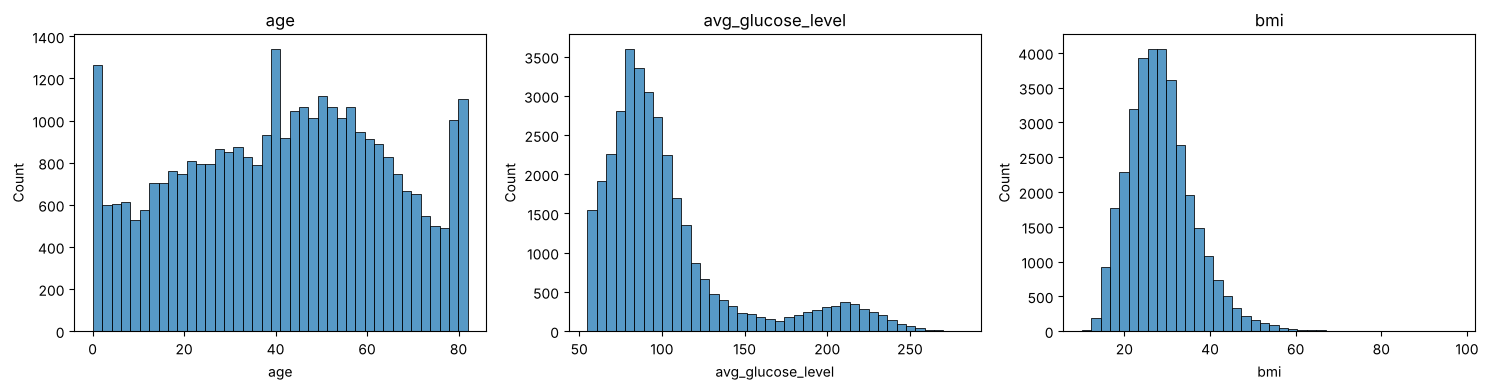

In [4]:
class StrokePlots:
    """Maakt de grafieken en tabellen voor de EDA."""

    def __init__(self, df, target="stroke"):
        self.df = df
        self.target = target

    def _grid(self, columns):
        """Maakt een rij subplots, één per kolom."""
        return plt.subplots(1, len(columns), figsize=(5 * len(columns), 4))[1]

    def plot_distributions(self, columns):
        """Histogrammen met de verdeling van numerieke kolommen."""
        for ax, col in zip(self._grid(columns), columns):
            sns.histplot(self.df[col], bins=40, ax=ax)
            ax.set_title(col)
        plt.tight_layout()
        plt.show()

    def outlier_table(self, columns):
        """Telt per kolom de outliers volgens de IQR-methode."""
        rows = {}
        for col in columns:
            q1, q3 = self.df[col].quantile([0.25, 0.75])
            iqr = q3 - q1
            low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            mask = (self.df[col] < low) | (self.df[col] > high)
            stroke_pct = (100 * self.df.loc[mask, self.target].mean()
                          if mask.any() else 0)
            rows[col] = {"Q1": q1, "Q3": q3, "ondergrens": low,
                         "bovengrens": high, "aantal outliers": mask.sum(),
                         "% outliers": 100 * mask.mean(),
                         "% stroke bij outliers": stroke_pct,
                         "scheefheid": self.df[col].skew()}
        return pd.DataFrame(rows).T.round(2)

    def plot_numeric(self, columns):
        """Boxplots van numerieke kolommen, gesplitst op stroke."""
        for ax, col in zip(self._grid(columns), columns):
            sns.boxplot(data=self.df, x=self.target, y=col, ax=ax)
            ax.set_title(col)
        plt.tight_layout()
        plt.show()

    def plot_binary(self, columns):
        """Percentage stroke per waarde van 0/1-kolommen."""
        for ax, col in zip(self._grid(columns), columns):
            (self.df.groupby(col)[self.target].mean() * 100).plot.bar(ax=ax)
            ax.set(title=col, ylabel="% stroke")
        plt.tight_layout()
        plt.show()

    def _to_category(self, prefix):
        """Zet dummy-kolommen terug om naar één categorische kolom."""
        cols = self.df.filter(like=prefix + "_")
        names = cols.idxmax(axis=1).str.replace(prefix + "_", "")
        # staan alle dummy's op 0, dan is de categorie onbekend
        return names.where(cols.sum(axis=1) == 1, "Unknown")

    def plot_categories(self, prefixes):
        """Percentage stroke per categorie van een categorische variabele."""
        for ax, prefix in zip(self._grid(prefixes), prefixes):
            groups = self.df.groupby(self._to_category(prefix))
            (groups[self.target].mean() * 100).plot.bar(ax=ax)
            ax.set(title=prefix, xlabel="", ylabel="% stroke")
        plt.tight_layout()
        plt.show()

    def plot_correlation(self):
        """Correlatie van iedere feature met stroke, gesorteerd."""
        corr = self.df.drop(columns="id").corr()[self.target]
        corr.drop(self.target).sort_values().plot.barh(figsize=(7, 8))
        plt.title("Correlatie met stroke")
        plt.tight_layout()
        plt.show()


NUM_COLS = ["age", "avg_glucose_level", "bmi"]
plots = StrokePlots(train.df)
plots.plot_distributions(NUM_COLS)

In [5]:
plots.outlier_table(NUM_COLS)

,Q1,Q3,ondergrens,bovengrens,aantal outliers,% outliers,% stroke bij outliers,scheefheid
age,24.00,59.00,-28.50,111.50,0.0,0.00,0.00,-0.08
avg_glucose_level,77.46,111.44,26.49,162.40,3641.0,10.85,4.48,1.72
bmi,23.30,32.80,9.05,47.05,769.0,2.29,1.30,0.92


**Bevindingen verdelingen en outliers**
- **age** is vrij gelijkmatig verdeeld tussen 0 en 82 jaar (scheefheid
  −0,08). Er zijn pieken bij de jongste kinderen en bij 80 tot 82 jaar. Dat
  de hoogste leeftijd precies 82 is, doet vermoeden dat oudere patiënten op
  82 zijn afgekapt. Volgens de IQR-methode zijn er geen outliers.
- **avg_glucose_level** is scheef naar rechts verdeeld (scheefheid 1,72) en
  heeft twee pieken. De grote groep zit rond de 80 tot 90 en een kleinere
  groep rond de 200 tot 220. Die tweede groep bestaat waarschijnlijk uit
  patiënten met diabetes. Volgens de IQR-methode zijn 3.641 patiënten (10,9%)
  een outlier, allemaal boven de 162,4. Van hen heeft 4,5% een stroke, drie
  keer zo vaak als gemiddeld (1,5%). Dit zijn dus geen meetfouten maar juist
  belangrijke patiënten. Die laten we daarom staan.
- **bmi** is licht scheef naar rechts verdeeld (scheefheid 0,92) met een
  piek rond de 27. Er zijn 769 outliers (2,3%), vooral boven de 47. Bij hen
  komt stroke niet vaker voor (1,3%). Een paar waarden zijn extreem hoog, tot
  97,6. Zo'n BMI is in het echt bijna onmogelijk. Die waarden kappen we in
  paragraaf 1.8 af.

Ontbrekende waarden zijn er niet, zoals we in paragraaf 1.2 al zagen.

## 1.6 Relaties tussen de features en stroke

### 1.6.1 Leeftijd, gemiddelde glucose en bmi

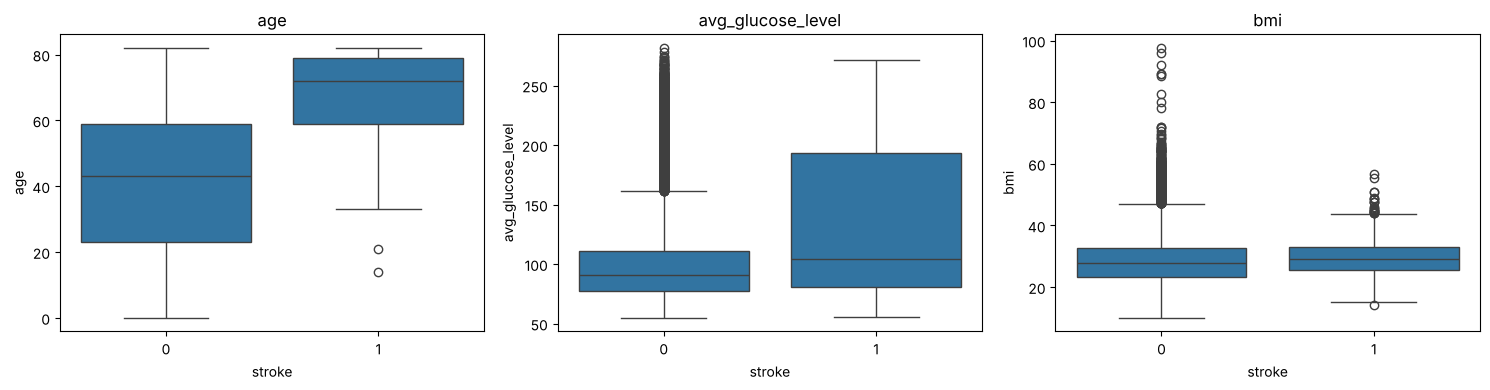

In [6]:
plots = StrokePlots(train.df)
plots.plot_numeric(["age", "avg_glucose_level", "bmi"])

Stroke-patiënten zijn duidelijk ouder dan patiënten zonder stroke. Bijna
driekwart (73%) van de stroke-patiënten is ouder dan 60 jaar.
Het gemiddelde glucosegehalte van stroke-patiënten (129,5) is ook een stuk
hoger dan dat van patiënten zonder stroke (103,2).
Bij BMI is er weinig verschil (gemiddeld 29,9 tegenover 28,6).

### 1.6.2 Hypertension en heart_disease

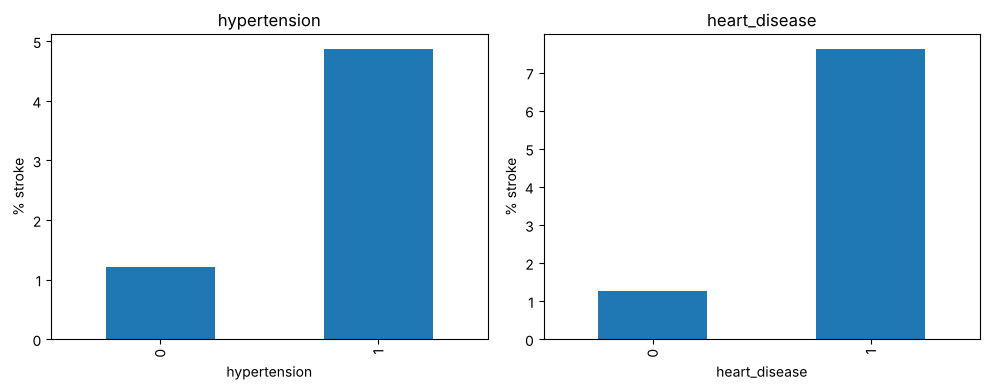

In [7]:
plots = StrokePlots(train.df)
plots.plot_binary(["hypertension", "heart_disease"])

Patiënten met hypertensie kregen in deze dataset ongeveer 4 keer zo vaak een herseninfarct als patiënten zonder. Bij een hartziekte is dit ongeveer 6 keer zo vaak. 
Toch krijgt ook in deze groepen het overgrote deel geen herseninfarct. Beide kenmerken lijken dus nuttig om het risico te voorspellen, maar zijn op zichzelf niet genoeg. 
Het gaat om een samenhang en niet per se om een oorzaak: ook leeftijd kan een rol spelen, omdat oudere mensen vaker hypertensie en hartziekten hebben.

### 1.6.3 Geslacht, getrouwd, werktype, woontype en rookstatus

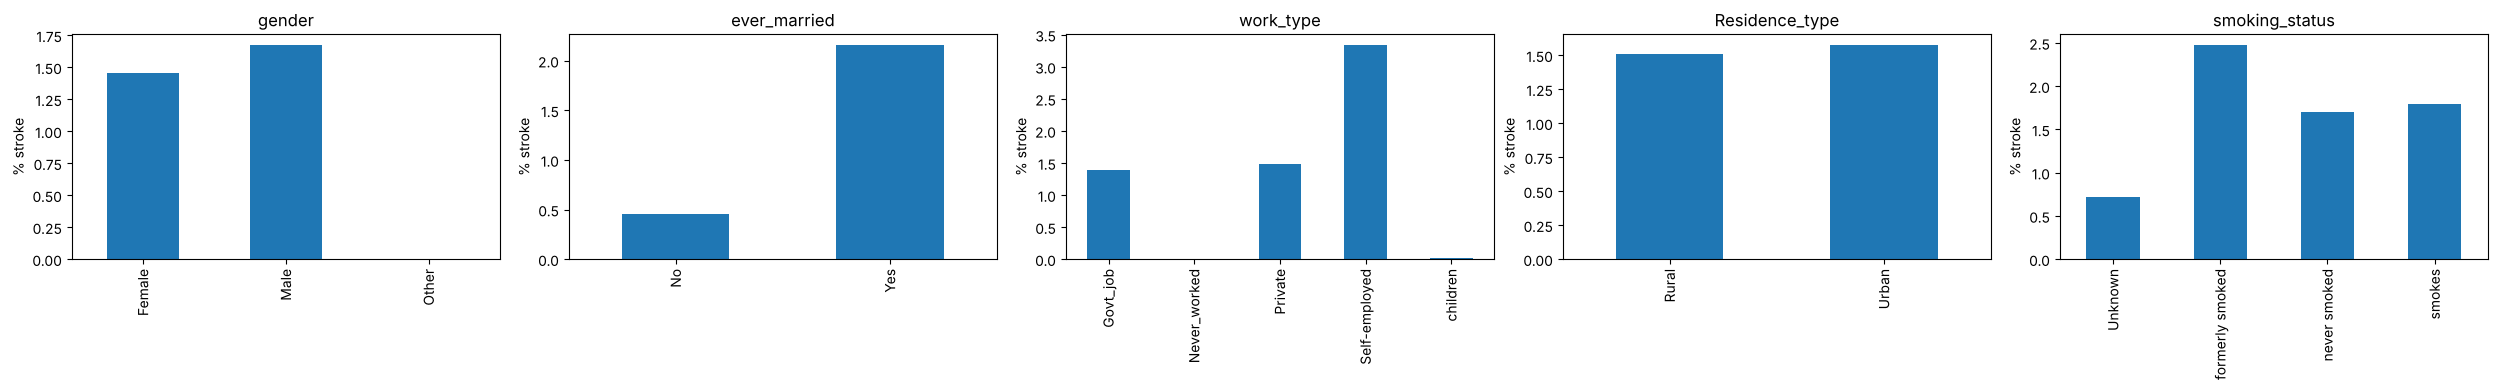

In [8]:
plots = StrokePlots(train.df)
plots.plot_categories(["gender", "ever_married", "work_type",
                       "Residence_type", "smoking_status"])

- **Geslacht** geeft weinig verschil: vrouwen 1,5% en mannen 1,7% stroke.
  De groep "Other" bestaat uit maar 6 personen; daar kunnen we geen
  conclusies uit trekken.
- **Getrouwd:** mensen die getrouwd zijn krijgen opvallend vaker
  een stroke dan mensen die nooit getrouwd zijn.
- **Werktype:** tussen private sector en overheid is bijna geen
  verschil. Zelfstandigen hebben het hoogste percentage. Bij
  "children" (de patiënt is zelf een kind) komt stroke bijna niet voor. De groep "never_worked" is te klein om een bevinding te maken.
- **Woontype** geeft geen verschil.
- **Roken:** ex-rokers hebben het hoogste percentage, hoger dan rokers
   en niet-rokers. Bij "Unknown" is het laag (0,7%).

Leeftijd speelt een belangrijke rol.
De groepen met een hoog percentage
stroke zijn ook de oudere groepen: getrouwden (mediaan 53 jaar), zelfstandigen
(62 jaar) en ex-rokers (56 jaar). 

Groepen met een laag percentage zijn juist
jong: kinderen (6 jaar), niet-getrouwden (18 jaar) en "Unknown" bij roken
(20 jaar). Het verschil tussen deze groepen komt dus waarschijnlijk voor een
groot deel door leeftijd en niet door de kenmerken zelf.

### 1.6.4 Correlaties

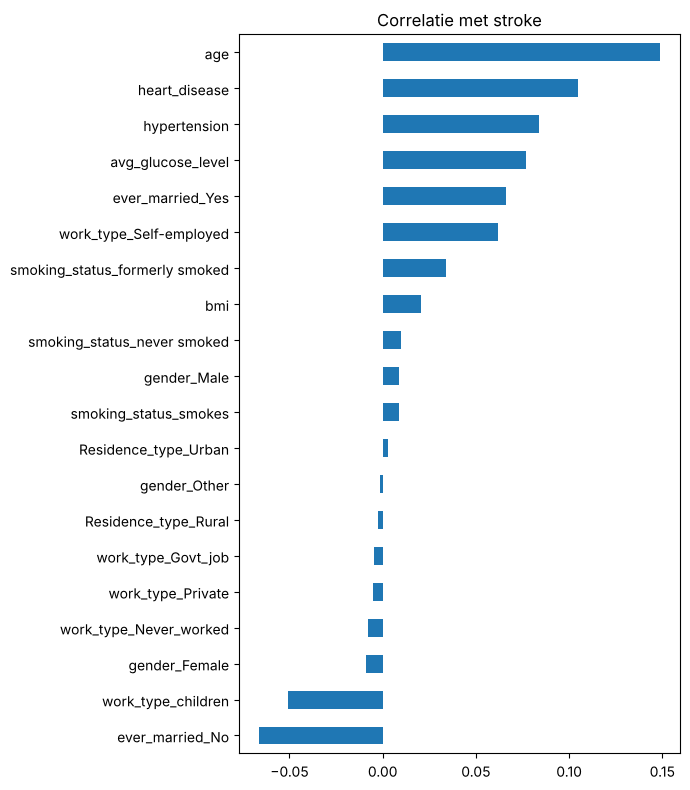

In [9]:
plots = StrokePlots(train.df)
plots.plot_correlation()

Correlatie met stroke

Wat opvalt, is dat zelfs de feature met de hoogste correlatie nog steeds een
lage correlatie heeft. Dat komt deels doordat stroke maar weinig voorkomt in de
data. Daarom kijken we vooral naar de volgorde van de features: welke hangen
relatief het sterkst samen met stroke?

- De sterkste positieve correlaties zijn age, heart_disease,
  hypertension en avg_glucose_level. Dit past bij wat we eerder in de
  boxplots en staafdiagrammen zagen.
- De sterkste negatieve correlaties zijn ever_married_No en
  work_type_children. Zoals we eerder zagen, zijn dit vooral jonge mensen.
  Ook hier speelt leeftijd dus weer een rol.
- Features met een correlatie van bijna 0, zoals Residence_type, zeggen
  bijna niks over stroke.

We zien ook dat sommige features elkaars spiegelbeeld zijn, zoals
ever_married_Yes en ever_married_No. Als de ene 1 is, is de andere altijd
0. Ze bevatten dus precies dezelfde informatie, alleen omgedraaid.

## 1.7 Belangrijkste bevindingen van de EDA

**De data is bruikbaar voor scikit-learn**
Er ontbreken geen waarden en alle kolommen zijn numeriek. De categorische
kolommen zijn al omgezet naar dummy-kolommen.

**De dataset is ongebalanceerd**
Maar ongeveer 1,5% van de patiënten heeft een stroke gehad. Een model dat
altijd "geen stroke" voorspelt, heeft dus al bijna alles goed, maar vindt geen
enkele stroke-patiënt. Daarom is accuracy hier geen goede maatstaf en hebben we
later technieken nodig om met deze ongebalanceerde dataset om te gaan.

**Leeftijd is de belangrijkste factor**
Stroke-patiënten zijn duidelijk ouder dan patiënten zonder stroke, en age
heeft de hoogste correlatie met stroke. Leeftijd speelt ook door in andere
kenmerken: getrouwden, zelfstandigen en ex-rokers hebben vaker een stroke,
maar zijn ook gemiddeld ouder. Kinderen hebben bijna nooit een stroke.

**Medische kenmerken hangen ook samen met stroke**
Patiënten met een hartziekte of hoge bloeddruk krijgen duidelijk vaker een
stroke. Ook een hoger glucosegehalte komt vaker voor bij stroke-patiënten.
Toch krijgt ook in deze groepen het grootste deel géén stroke.

**Sommige kenmerken zeggen weinig**
Woontype (stad of platteland) en geslacht laten bijna geen verschil zien. BMI
hangt ook maar zwak samen met stroke.

**Aandachtspunten voor het opschonen**
- id is alleen een volgnummer en zegt niets over de patiënt.
- Bij ongeveer 30% van de patiënten is het rookgedrag onbekend (alle
  rookkolommen staan op 0).
- Sommige groepen zijn erg klein, zoals gender_Other en
  work_type_Never_worked.
- bmi heeft een aantal extreem hoge waarden die mogelijk meetfouten zijn.
- avg_glucose_level is scheef verdeeld en heeft volgens de IQR-methode
  veel outliers. Dit zijn echter juist patiënten met een hoger risico,
  dus die laten we staan.
- Sommige dummy-kolommen zijn elkaars spiegelbeeld (zoals
  ever_married_Yes en ever_married_No) en bevatten dus dubbele
  informatie.

## 1.8 Opschonen van de data

**Wat halen we weg?**
- De kolom id halen we weg, omdat het alleen een volgnummer is en niks zegt
  over de patiënt. De id's van de testset bewaren we wel apart, want die hebben
  we nodig voor de Kaggle-inlevering.
- De groep gender_Other bestaat maar uit 6 patiënten, en geen van hen heeft
  een stroke. Daar kan een model niks van leren. Daarom halen we deze 6 rijen
  weg uit de trainingsdata. Daarna is de kolom overal 0 en dus ook nutteloos,
  dus die gaat ook weg. In de testset zit 1 persoon met "Other"; die wordt
  hierdoor als vrouw behandeld. Dat is een bewuste keuze.
- Sommige dummy-kolommen zijn elkaars spiegelbeeld: als de ene 1 is, is de
  andere 0. Ze bevatten dus dubbele informatie. Daarom halen we er telkens 1
  weg: ever_married_No, Residence_type_Rural en gender_Female. Dubbele
  kolommen kunnen bij sommige modellen voor problemen zorgen. Bij KNN tellen
  ze bijvoorbeeld dubbel mee in de afstand.

**Wat passen we aan?**
- Bij bmi zitten een aantal extreme waarden, tot bijna 98. Dat is
  waarschijnlijk een meetfout. We kappen de BMI af op 60: alles boven de 60
  wordt 60. We halen deze rijen niet weg, omdat we in de testset ook geen rijen
  mogen weghalen. Afkappen kunnen we in beide sets op dezelfde manier doen.

**Wat laten we staan?**
- Bij ongeveer 30% is het rookgedrag onbekend. Dat is te veel om weg te
  gooien, en ook in de testset komt het voor. Als alle rookkolommen 0 zijn,
  betekent dat gewoon "onbekend".
- work_type_Never_worked is een kleine groep, maar wel een echte en logische
  groep, dus die blijft.
- Residence_type heeft bijna geen correlatie met stroke, maar dat betekent
  niet automatisch dat de kolom nutteloos is. Die laten we dus staan.
- Er zijn geen dubbele rijen in de data.


In [10]:
train = StrokeData("train.csv")
train.clean(is_train=True)
test = StrokeData("test.csv")
test.clean(is_train=False)

print("Train:", train.df.shape, ", Test:", test.df.shape)
print("Dubbele rijen in train:", train.df.duplicated().sum())
print("Hoogste BMI:", train.df["bmi"].max())

Train: (33544, 17) , Test: (8388, 16)
Dubbele rijen in train: 0
Hoogste BMI: 60.0


## 1.9 Standaardiseren

**Wat is het?**
Bij standaardiseren zet je elke kolom op dezelfde schaal: gemiddelde 0 en
standaarddeviatie 1. Je trekt het gemiddelde van de kolom af van de waarde en
deelt de uitkomst door de standaarddeviatie. 

$$z = \frac{x - \mu}{\sigma}$$

Hierbij is $x$ de originele waarde, $\mu$ het gemiddelde en $\sigma$ de
standaarddeviatie van de kolom.

**Waarom en wanneer?**
Onze kolommen hebben verschillende schalen (bmi tot 60, avg_glucose_level
tot 282, dummy's 0 of 1). Zonder standaardiseren telt een kolom met grote
getallen zwaarder mee. Dat is een probleem bij KNN en SVM (die rekenen met
afstanden) en bij Logistic Regression (gradient descent en regularisatie).
Bij beslisbomen maakt het niet uit, want die splitsen op een kolom tegelijk.

**Voor deze dataset**
Het voegt waarde toe, omdat we KNN, SVM en Logistic Regression gebruiken.
Hieronder laten we met de functie standardize() het effect zien op de drie
numerieke kolommen age, avg_glucose_level en bmi. In de modellen zelf
(paragraaf 3.2) zit de StandardScaler in de pipeline. Die standaardiseert
alle features, dus ook de dummy-kolommen, zodat iedere feature dezelfde
schaal heeft. Het gemiddelde en de standaarddeviatie worden steeds alleen op
de trainingsdata (de trainfolds) berekend, om data leakage te voorkomen.


In [11]:
def standardize(train_df, test_df, columns=NUM_COLS):
    """Standaardiseert kolommen met de statistieken van de trainset."""
    scaler = StandardScaler().fit(train_df[columns])
    train_std, test_std = train_df.copy(), test_df.copy()
    train_std[columns] = scaler.transform(train_df[columns])
    test_std[columns] = scaler.transform(test_df[columns])
    return train_std, test_std


train_std, test_std = standardize(train.df, test.df)

display(train.df[NUM_COLS].describe().loc[["mean", "std"]].round(2))
display(train_std[NUM_COLS].describe().loc[["mean", "std"]].round(2))

,age,avg_glucose_level,bmi
mean,41.82,103.59,28.59
std,22.48,42.13,7.70


,age,avg_glucose_level,bmi
mean,-0.0,0.0,0.0
std,1.0,1.0,1.0


# 2. Evaluatie (opdracht 2)

## 2.1 Confusion matrix

Een model kan op vier manieren voorspellen (Radhakrishnan, 2023b).

|                     | Voorspeld: geen stroke | Voorspeld: stroke |
|---------------------|------------------------|-------------------|
| **Echt: geen stroke** | TN (True Negative)   | FP (False Positive) |
| **Echt: stroke**      | FN (False Negative)  | TP (True Positive)  |

- **TP**: stroke-patiënt goed gevonden.
- **TN**: gezond persoon terecht als gezond gezien.
- **FP**: vals alarm, het model zegt stroke maar de persoon is gezond.
- **FN**: gemist, de persoon heeft een stroke maar het model ziet het niet.
  Dit is het gevaarlijkst, want deze patiënt krijgt geen hulp.

## 2.2 Metrics

- **Accuracy** = (TP + TN) / alle patiënten
  Hoeveel procent van alle voorspellingen is goed?
- **Precision** = TP / (TP + FP)
  Van de mensen die het model als stroke aanwijst: hoeveel hebben er echt een?
- **Recall** = TP / (TP + FN)
  Van alle echte stroke-patiënten: hoeveel vindt het model?
- **F1-score** = 2 × (precision × recall) / (precision + recall)
  Combineert precision en recall in één getal. Hij is alleen hoog als
  beide hoog zijn.

**Waarom accuracy hier niet werkt:** maar 1,5% van de patiënten heeft een
stroke. Een model dat bij iedereen "geen stroke" zegt, heeft dus al 98,5%
accuracy, maar vindt niemand. Recall, precision en F1 zijn dan allemaal 0.

## 2.3 Metrics toegepast op Logistic Regression

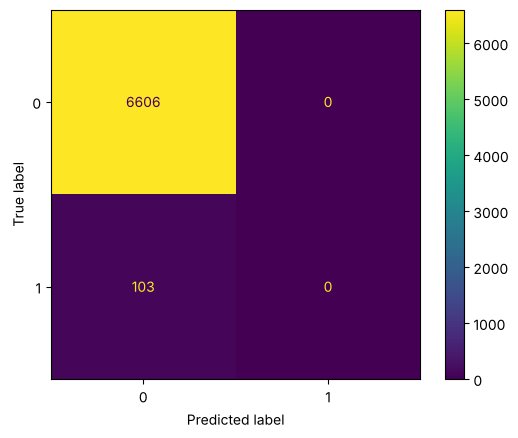

              precision    recall  f1-score   support

           0      0.985     1.000     0.992      6606
           1      0.000     0.000     0.000       103

    accuracy                          0.985      6709
   macro avg      0.492     0.500     0.496      6709
weighted avg      0.970     0.985     0.977      6709



In [12]:
X = train.df.drop(columns="stroke")
y = train.df["stroke"]

# 80% trainen en 20% valideren, met evenveel stroke in beide delen
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)


def evaluate(model):
    """Traint een model, toont de confusion matrix en de metrics."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
    plt.show()
    print(classification_report(y_val, y_pred, digits=3, zero_division=0))


evaluate(make_pipeline(StandardScaler(), LogisticRegression()))

We hebben de trainingsdata gesplitst in 80% om te trainen en 20% om te
valideren. In het validatiedeel zitten 6.606 patiënten zonder stroke en 103
met een stroke.

In de confusion matrix zien we dat het model bij iedereen "geen stroke"
voorspelt:
- **TN = 6.606**: alle gezonde mensen zijn goed voorspeld.
- **TP = 0**: geen enkele stroke-patiënt is gevonden.
- **FN = 103**: alle stroke-patiënten zijn gemist.
- **FP = 0**: er is geen vals alarm, omdat het model nooit "stroke" zegt.

De accuracy is 98,5%. Dat lijkt heel goed, maar precision, recall en F1 voor
stroke zijn allemaal 0. Het model heeft geleerd dat het bijna altijd goed zit
als het "geen stroke" zegt, omdat stroke zo weinig voorkomt. Voor artsen is
dit model dus nutteloos: het vindt niemand die risico loopt.

Dit laat zien dat accuracy bij ongebalanceerde data een misleidende maatstaf
is. 

## 2.4 Waarom F1-score?

F1-score is de beste maatstaf, om drie redenen:

1. **De data is ongebalanceerd.** Maar 1,5% heeft een stroke. Accuracy is
   daardoor misleidend: een model dat bij iedereen "geen stroke" zegt, haalt
   98,5% accuracy maar vindt niemand.

2. **Precision en recall zijn allebei belangrijk.** Een hoge recall betekent
   dat we weinig stroke-patiënten missen. Een hoge precision betekent weinig
   vals alarm. Los zijn ze makkelijk te foppen: wie bij iedereen "stroke"
   zegt, heeft een recall van 100%, maar dan is bijna elk alarm vals.
   
3. **F1 combineert ze eerlijk.** F1 is alleen hoog als precision én recall
   allebei hoog zijn. Een model kan een slechte score op de ene dus niet
   goedmaken met een goede score op de andere. Bovendien telt F1 de vele
   goed voorspelde gezonde mensen (TN) niet mee, zodat het echt draait om het
   vinden van stroke-patiënten.

# 3. Modelleren (opdracht 3)

## 3.1 Imbalanced dataset

**Waarom is de dataset ongebalanceerd?**
Maar 1,5% van de patiënten in de data heeft een herseninfarct gehad. Dat komt
doordat een herseninfarct in het echt ook weinig voorkomt. Het probleem
hiervan zagen we in paragraaf 2.3: een model leert dat het bijna altijd goed zit
als het "geen stroke" zegt, en vindt daardoor niemand.

**Technieken om dit op te lossen**
- **Oversampling (SMOTE):** maakt extra, nep stroke-patiënten
  (Chawla et al., 2002). Hij neemt
  een stroke-patiënt en een vergelijkbare stroke-patiënt, en maakt daar een
  nieuwe patiënt tussenin. Zo heeft het model meer stroke-voorbeelden om van
  te leren.
- **Undersampling:** haalt een deel van de gezonde patiënten weg, zodat de
  groepen meer in balans zijn. Dit is snel, maar je gooit wel informatie weg.
- **Class weights:** het model krijgt een grotere straf als het een
  stroke-patiënt fout voorspelt. Daardoor let het beter op die groep. Dit kan
  niet bij elk model. KNN heeft bijvoorbeeld geen class weights, en bij
  Gradient Boosting kan het alleen via `sample_weight`.
- **Threshold aanpassen:** een model berekent eigenlijk een kans, zoals 0,23.
  Normaal zegt het pas "stroke" bij een kans van 0,5 of hoger. Bij een
  zeldzame groep wordt dat bijna nooit gehaald. Als je de grens verlaagt,
  bijvoorbeeld naar 0,2, zegt het model vaker "stroke".

Onze keuze :
We gebruiken SMOTE en threshold aanpassen, omdat deze twee bij alle
modellen werken. SMOTE passen we alleen toe op de trainingsdata en nooit op
de validatiedata, anders testen we op nep-patiënten en lijkt de score beter
dan hij is.

## 3.2 Cross-validation en hyperparameter tuning

**Cross-validation:**
We verdelen de trainingsdata in 5 stukken (folds). Het model wordt 5 keer
getraind: elke keer op 4 stukken, en getest op het 5e stuk. Elke ronde is een
ander stuk het testdeel. Het gemiddelde van de 5 scores is betrouwbaarder dan
1 losse score, omdat het minder afhangt van toeval. We gebruiken stratified
cross-validation: elk stuk krijgt ongeveer evenveel stroke-patiënten (1,5%).
Dat is belangrijk, omdat er maar weinig stroke-patiënten zijn.

**Hyperparameter tuning:**
Hyperparameters zijn instellingen die we zelf kiezen voordat het model leert,
zoals het aantal buren bij KNN. Parameters leert het model zelf uit de data.
Met GridSearchCV proberen we alle combinaties van hyperparameters die we
opgeven, elke keer met cross-validation. De combinatie met de hoogste
gemiddelde F1-score is het beste.

De pipeline met SMOTE bouwen we met imbalanced-learn (Lemaître et al., 2017).
Voor de modellen, de cross-validation en de grid search gebruiken we
scikit-learn (Pedregosa et al., 2011).

In [13]:
X = train.df.drop(columns="stroke")
y = train.df["stroke"]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
RESULTS = {}


class ModelTuner:
    """Tunet een model met SMOTE, cross-validation en threshold tuning.

    De pipeline bestaat uit (optioneel) een StandardScaler, SMOTE en het
    model. Omdat SMOTE in de pipeline zit, wordt het alleen op de trainfolds
    toegepast en nooit op de validatiefold.
    """

    def __init__(self, name, model, params, scale=True):
        self.name = name
        steps = [("smote", SMOTE(random_state=42)), ("model", model)]
        if scale:
            steps.insert(0, ("scaler", StandardScaler()))
        self.pipe = Pipeline(steps)
        # hyperparameters zonder prefix horen bij het model zelf
        self.params = {k if "__" in k else f"model__{k}": v
                       for k, v in params.items()}

    def tune(self):
        """Zoekt met GridSearchCV de hyperparameters met de hoogste F1."""
        self.grid = GridSearchCV(self.pipe, self.params, scoring="f1",
                                 cv=CV, n_jobs=-1)
        self.grid.fit(X, y)
        print("Beste hyperparameters:", self.grid.best_params_)
        print(f"F1 bij threshold 0,5: {self.grid.best_score_:.3f}")

    def tune_threshold(self):
        """Zoekt de threshold met de hoogste F1 op cross-validation-kansen."""
        proba = cross_val_predict(self.grid.best_estimator_, X, y, cv=CV,
                                  method="predict_proba", n_jobs=-1)[:, 1]
        # we proberen alle thresholds van 0,05 tot en met 0,95
        thresholds = np.arange(0.05, 0.96, 0.01)
        scores = [f1_score(y, proba >= t) for t in thresholds]
        self.threshold = float(thresholds[np.argmax(scores)])
        self.f1 = max(scores)
        print(f"Beste threshold: {self.threshold:.2f} -> F1: {self.f1:.3f}")
        ConfusionMatrixDisplay.from_predictions(y, proba >= self.threshold)
        plt.show()

    def submit(self):
        """Voorspelt test.csv, slaat de submission op en bewaart de score."""
        proba = self.grid.best_estimator_.predict_proba(test.df)[:, 1]
        pred = (proba >= self.threshold).astype(int)
        file = f"submission_{self.name}.csv"
        pd.DataFrame({"id": test.ids, "stroke": pred}).to_csv(file,
                                                              index=False)
        RESULTS[self.name] = {"F1 notebook": round(self.f1, 3),
                              "threshold": round(self.threshold, 2),
                              "hyperparameters": self.grid.best_params_}
        print(f"Opgeslagen: {file} ({pred.sum()} keer stroke voorspeld)")

    def run(self):
        """Voert tuning, threshold tuning en de submission na elkaar uit."""
        self.tune()
        self.tune_threshold()
        self.submit()

## 3.3 K-Nearest Neighbors

**Hoe werkt het?**
KNN gaat ervan uit dat patiënten die op elkaar lijken, waarschijnlijk dezelfde
uitkomst hebben. Voor een nieuwe patiënt berekent het model de afstand tot
alle patiënten in de trainingsdata. Daarna pakt het de K patiënten die het
dichtstbij liggen (de buren) en kijkt wat die hebben (Hastie et al.,
2009). Hebben bijvoorbeeld 9
van de 15 buren een stroke, dan is de kans op stroke 9/15 = 0,6.

**Afstand: euclidean en manhattan**
Stel patiënt A heeft (3, 1) en patiënt B heeft (6, 5).
- **Euclidean** is de rechte lijn tussen twee punten:
  √((6−3)² + (5−1)²) = √25 = 5
- **Manhattan** is de afstand langs de assen, zoals lopen door rechte
  straten: |6−3| + |5−1| = 7

Bij euclidean tellen grote verschillen zwaarder mee, omdat ze in het kwadraat
gaan.

**Waarom standaardiseren?**
KNN draait helemaal om afstand. Zonder standaardiseren telt een kolom met
grote getallen, zoals glucose, veel zwaarder mee dan een kolom met 0 en 1,
zoals hartziekte. Dan bepaalt glucose bijna alleen wie de buren zijn. Na
standaardiseren telt elke kolom eerlijk mee.

**Regularisatie**
KNN heeft geen strafterm, maar de K werkt als regularisatie. Bij een kleine K
volgt het model elke losse patiënt, ook uitschieters, en dat geeft
overfitting. Bij een grotere K kijkt het model naar een grotere groep en
middelt het de ruis weg. Een te grote K geeft underfitting.

**Hyperparameters die we tunen:** n_neighbors (de K), metric
(euclidean of manhattan) en de hoeveelheid SMOTE.

Beste hyperparameters: {'model__metric': 'manhattan', 'model__n_neighbors': 400, 'smote__sampling_strategy': 0.3}
F1 bij threshold 0,5: 0.122


Beste threshold: 0.52 -> F1: 0.124


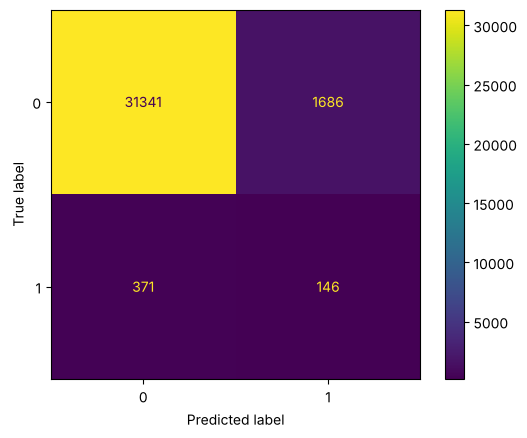

Opgeslagen: submission_knn.csv (485 keer stroke voorspeld)


In [14]:
knn = ModelTuner("knn", KNeighborsClassifier(),
                 {"n_neighbors": [100, 200, 300, 400],
                  "metric": ["euclidean", "manhattan"],
                  "smote__sampling_strategy": [0.3, 0.5]})
knn.run()

### 3.3.1 Resultaat en voor- en nadelen
**Resultaat**
De beste KNN gebruikt de **manhattan-afstand met k = 400** en SMOTE 0,3. Met
de standaard threshold is de F1-score 0,122, met de beste threshold (0,52)
**0,124**. Op de testset voorspelt het model 485 keer stroke.

Een grote k werkt hier het best. Zelfs na SMOTE is maar ongeveer een kwart
van de patiënten een stroke-patiënt. In een kleine buurt zitten daardoor
maar een paar stroke-patiënten en dan bepaalt toeval de uitkomst. Een grote
k middelt die ruis weg. k = 400 is wel de grootste waarde die we geprobeerd
hebben, dus een nog grotere k is misschien beter. Het voorspellen wordt dan
wel trager. Manhattan wint van euclidean, waarschijnlijk omdat één groot
verschil in één feature bij manhattan minder zwaar telt. Bij euclidean gaat
dat verschil in het kwadraat.

**Voordelen**
- Simpel en intuïtief. Patiënten die op elkaar lijken krijgen dezelfde
  voorspelling.
- Er is eigenlijk geen training. Het model onthoudt alleen de data.
- Kan ingewikkelde, niet-lineaire grenzen volgen.
- Gaat niet uit van een bepaalde verdeling van de data.

**Nadelen**
- Traag bij het voorspellen, want voor iedere nieuwe patiënt moet de
  afstand tot alle 33.000 trainingspatiënten berekend worden.
- De hele trainingsset met patiëntgegevens moet bij het model bewaard
  blijven. Dat is lastig voor de privacy.
- Standaardiseren is verplicht.
- Bij veel features worden afstanden minder betekenisvol (de curse of
  dimensionality).
- Het model laat niet zien welke features belangrijk zijn.
- Bij ongebalanceerde data zijn de buren bijna altijd gezond. Zonder SMOTE
  en een grote k vindt KNN bijna geen stroke-patiënten.

## 3.4 Logistic Regression

**Hoe werkt het?**
Logistic Regression berekent voor elke patiënt de kans op een stroke. Dat
gaat in twee stappen.

*Stap 1:* het model geeft elke feature een gewicht en telt alles bij elkaar
op:

$$z = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_n x_n$$

Hier zijn $x_1, x_2, \dots$ de features (zoals leeftijd en glucose) en
$b_1, b_2, \dots$ de gewichten. $b_0$ is een vast startgetal (de intercept).
Een groot positief gewicht betekent dat die feature de kans op stroke
verhoogt.

*Stap 2:* de uitkomst $z$ kan elk getal zijn, maar een kans moet tussen 0 en
1 liggen. Daarom gaat $z$ door de sigmoid-functie:

$$p = \frac{1}{1 + e^{-z}}$$

Een heel negatieve $z$ geeft een kans dicht bij 0, een heel positieve $z$
een kans dicht bij 1. Bijvoorbeeld: $z = 0{,}5$ geeft
$p = 1 / (1 + e^{-0,5}) \approx 0{,}62$, dus 62% kans op stroke.

Is de kans hoger dan de threshold, dan voorspelt het model "stroke".

**De loss-functie**
Om de beste gewichten te vinden, moet het model weten hoe fout het zit.
Dat meet de loss-functie. Bij Logistic Regression is dat de log loss
(binary cross-entropy):

$$L = -\frac{1}{n} \sum_{i=1}^{n} \Big[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \Big]$$

- $n$ = aantal patiënten
- $y_i$ = de echte uitkomst van patiënt $i$ (0 of 1)
- $p_i$ = de voorspelde kans op stroke

Per patiënt valt steeds één van de twee delen weg:
- Heeft de patiënt een stroke ($y = 1$), dan telt alleen $-\log(p)$.
- Heeft de patiënt geen stroke ($y = 0$), dan telt alleen $-\log(1 - p)$.

Voorbeeld voor een stroke-patiënt:
- Model zegt $p = 0{,}9$: loss $= -\log(0{,}9) \approx 0{,}11$, klein, goed
  voorspeld.
- Model zegt $p = 0{,}1$: loss $= -\log(0{,}1) \approx 2{,}30$, groot,
  zwaar gestraft.

Hoe zekerder het model van een foute voorspelling is, hoe groter de straf.
Het doel van het trainen is de gewichten zo kiezen dat deze loss zo laag
mogelijk is.

### 3.4.1 Linkfunctie en aannames
**De logit als linkfunctie**
Logistic Regression is een gegeneraliseerd lineair model. Het lineaire deel
$z$ voorspelt niet direct de kans, maar de log-odds van de kans. Die omzetting
heet de linkfunctie, en bij Logistic Regression is dat de logit

$$\text{logit}(p) = \log\left(\frac{p}{1 - p}\right) = b_0 + b_1 x_1 + \dots + b_n x_n$$

$\frac{p}{1-p}$ zijn de odds, de kans op stroke gedeeld door de kans op geen
stroke. De sigmoid uit de vorige alinea is precies de omgekeerde functie van
de logit. Dit maakt de gewichten goed uit te leggen. Als feature $x_j$ met 1
stijgt, stijgen de log-odds met $b_j$. De odds worden dan vermenigvuldigd met
$e^{b_j}$, de **odds ratio** (Hastie et al., 2009).

**Aannames**
Logistic Regression werkt het best als aan de volgende aannames is voldaan.
1. *De afhankelijke variabele is binair.* Dat klopt, stroke is 0 of 1.
2. *De observaties zijn onafhankelijk.* Iedere rij is een andere patiënt,
   dus dat nemen we aan.
3. *Er is een lineair verband tussen de features en de log-odds.* Dus niet
   met de kans zelf. Voor leeftijd en glucose is dat redelijk, want het
   risico stijgt daar geleidelijk mee.
4. *Geen sterke multicollineariteit.* Features die bijna hetzelfde zeggen
   maken de gewichten onbetrouwbaar. De perfecte spiegelbeelden van de
   dummy-kolommen hebben we in paragraaf 1.8 al verwijderd.
   `work_type_children` en `ever_married_Yes` hangen nog wel samen met
   leeftijd.
5. *Genoeg data per feature.* Een vuistregel is minstens 10 stroke-patiënten
   per feature (Peduzzi et al., 1996). Wij hebben 517 stroke-patiënten en 16
   features, dus ongeveer 32 per feature.

In tegenstelling tot lineaire regressie hoeven de residuen niet normaal
verdeeld te zijn.

### 3.4.2 Gradient descent
Gradient descent is de manier waarop het model de beste gewichten vindt
(Radhakrishnan, 2025),
oftewel de gewichten met de laagste loss. Je kunt het vergelijken met een berg
afdalen in de mist: je ziet de bodem niet, maar je voelt wel welke kant het
naar beneden gaat. Je zet een stapje die kant op, en herhaalt dat totdat je
onderaan bent.

De "helling" is de afgeleide van de loss (de gradient). Voor Logistic
Regression is dat:

$$\frac{\partial L}{\partial b_j} = \frac{1}{n} \sum_{i=1}^{n} (p_i - y_i)\, x_{ij}
\qquad \text{en voor de intercept:} \qquad
\frac{\partial L}{\partial b_0} = \frac{1}{n} \sum_{i=1}^{n} (p_i - y_i)$$

Daarna wordt elk gewicht een stapje aangepast:

$$b_j = b_j - \alpha \cdot \frac{\partial L}{\partial b_j}$$

$\alpha$ is de learning rate: hoe groot de stap is. Is die te groot, dan
schiet je over de bodem heen. Is die te klein, dan duurt het heel lang.

**Rekenvoorbeeld**
We nemen 2 patiënten en 1 feature (gestandaardiseerde leeftijd):

| Patiënt | leeftijd $x$ | stroke $y$ |
|---|---|---|
| 1 | 1 (ouder) | 1 |
| 2 | −1 (jonger) | 0 |

*Start:* $b_0 = 0$, $b_1 = 0$ en learning rate $\alpha = 0{,}5$.
Dan is $z = 0$ voor beide patiënten, dus $p = 0{,}5$.

Loss: $L = -\frac{1}{2}\big[\log(0{,}5) + \log(1 - 0{,}5)\big] \approx 0{,}693$

*Gradient berekenen:*

$$\frac{\partial L}{\partial b_1} = \frac{1}{2}\big[(0{,}5 - 1)\cdot 1 + (0{,}5 - 0)\cdot(-1)\big] = \frac{1}{2}(-0{,}5 - 0{,}5) = -0{,}5$$

$$\frac{\partial L}{\partial b_0} = \frac{1}{2}\big[(0{,}5 - 1) + (0{,}5 - 0)\big] = 0$$

*Gewichten aanpassen:*

$$b_1 = 0 - 0{,}5 \cdot (-0{,}5) = 0{,}25 \qquad b_0 = 0 - 0{,}5 \cdot 0 = 0$$

*Nieuwe kansen:*
- Patiënt 1: $z = 0{,}25$, dus $p = 1/(1 + e^{-0,25}) \approx 0{,}56$
- Patiënt 2: $z = -0{,}25$, dus $p \approx 0{,}44$

Nieuwe loss: $L = -\frac{1}{2}\big[\log(0{,}56) + \log(1 - 0{,}44)\big] \approx 0{,}576$

De loss is gedaald van 0,693 naar 0,576. Het model heeft geleerd dat een hogere
leeftijd de kans op stroke verhoogt ($b_1$ is positief geworden). De oudere
patiënt krijgt nu een hogere kans en de jongere een lagere. Gradient descent
herhaalt deze stap vaak, totdat de loss bijna niet meer daalt.

### 3.4.3 Regularisatie
Bij regularisatie tellen we een extra straf op bij de loss. Die straf wordt
groter als de gewichten groter worden. Het model moet dus een balans vinden
tussen een lage loss en kleine gewichten.

Er zijn twee vormen:

*L2-regularisatie (Ridge)*

$$L_{totaal} = L + \lambda \sum_{j=1}^{n} b_j^2$$

De straf is de som van de gewichten in het kwadraat. Grote gewichten worden
hierdoor extra zwaar gestraft. Effect: alle gewichten worden kleiner, maar ze
worden bijna nooit precies 0. Elke feature blijft dus een beetje meetellen.

*L1-regularisatie (Lasso)*

$$L_{totaal} = L + \lambda \sum_{j=1}^{n} |b_j|$$

De straf is de som van de absolute gewichten. Effect: gewichten van
onbelangrijke features worden precies 0. L1 gooit dus features weg en doet
eigenlijk automatisch feature selection.

$\lambda$ (lambda) bepaalt hoe zwaar de straf is. In scikit-learn heet de
instelling $C$, en die werkt andersom: $C = 1/\lambda$. Een kleine $C$
betekent dus een zware straf.

**Voorbeeld:** neem een gewicht van 3 en een gewicht van 0,5.
- L1-straf: $|3| = 3$ en $|0{,}5| = 0{,}5$
- L2-straf: $3^2 = 9$ en $0{,}5^2 = 0{,}25$

L2 straft het grote gewicht dus veel harder dan L1.

**Regularisatie en overfitting**
Bij overfitting leert het model de trainingsdata te goed, inclusief ruis en
toevallige patronen. Dat zie je vaak terug in hele grote gewichten: het model
reageert dan te sterk op kleine verschillen. Regularisatie houdt de gewichten
klein, waardoor het model eenvoudiger wordt en beter werkt op nieuwe
patiënten. Maar met te veel regularisatie (een te kleine $C$) wordt het model
te simpel en mist het echte patronen. Dat is underfitting. Met
hyperparameter tuning zoeken we de $C$ die precies in het midden zit.

**Hyperparameters die we tunen:** `C` (sterkte van de regularisatie) en
`penalty` (L1 of L2).

Beste hyperparameters: {'model__C': 10, 'model__penalty': 'l2'}
F1 bij threshold 0,5: 0.089


Beste threshold: 0.81 -> F1: 0.146


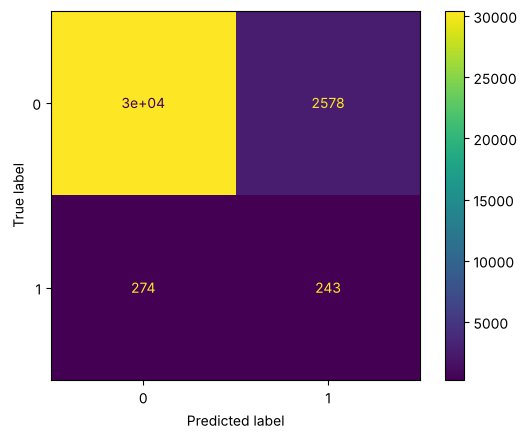

Opgeslagen: submission_logreg.csv (726 keer stroke voorspeld)


In [15]:
logreg = ModelTuner("logreg", LogisticRegression(solver="liblinear"),
                    {"C": [0.01, 0.1, 1, 10, 100],
                     "penalty": ["l1", "l2"]})
logreg.run()

### 3.4.4 Coëfficiënten en odds ratios
Hieronder staan de gewichten van het beste model. Omdat de features vooraf
gestandaardiseerd zijn, betekent een gewicht hier het effect van **één
standaarddeviatie** stijging. Bij leeftijd is dat ongeveer 22,5 jaar. Een
positief gewicht (odds ratio boven 1) verhoogt het risico, een negatief
gewicht (odds ratio onder 1) verlaagt het. Ook de 0/1-kolommen zijn
gestandaardiseerd. Hoe we die lezen, staat onder de tabel.

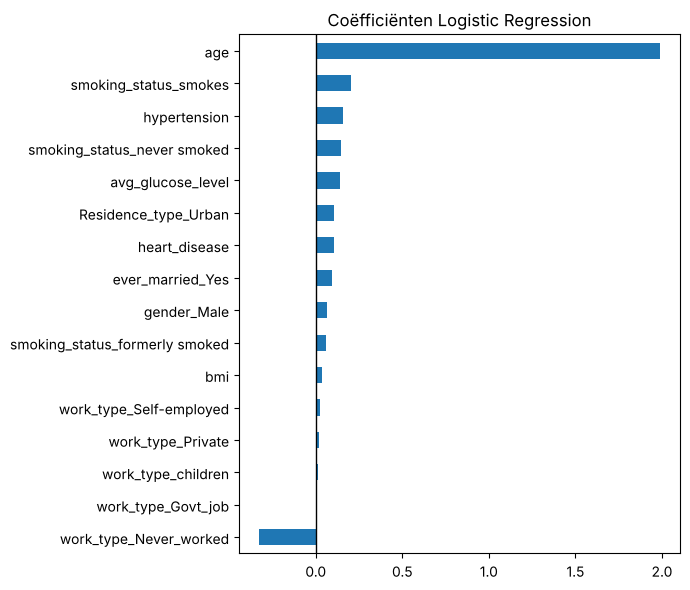

,coëfficiënt,odds ratio
work_type_Never_worked,-0.328,0.720
work_type_Govt_job,0.001,1.001
work_type_children,0.012,1.012
work_type_Private,0.017,1.017
work_type_Self-employed,0.024,1.024
bmi,0.036,1.036
smoking_status_formerly smoked,0.058,1.059
gender_Male,0.066,1.068
ever_married_Yes,0.095,1.100
heart_disease,0.104,1.109


In [16]:
def show_coefficients(tuner):
    """Toont de gewichten en odds ratios van een Logistic Regression."""
    model = tuner.grid.best_estimator_.named_steps["model"]
    coefs = pd.DataFrame({"coëfficiënt": model.coef_[0]}, index=X.columns)
    coefs["odds ratio"] = np.exp(coefs["coëfficiënt"])
    coefs = coefs.sort_values("coëfficiënt")
    coefs["coëfficiënt"].plot.barh(figsize=(7, 6))
    plt.axvline(0, color="black", linewidth=1)
    plt.title("Coëfficiënten Logistic Regression")
    plt.tight_layout()
    plt.show()
    return coefs.round(3)


show_coefficients(logreg)

**Interpretatie van de coëfficiënten**
- **age** heeft veruit het grootste gewicht (1,99). Een patiënt die één
  standaarddeviatie (ongeveer 22,5 jaar) ouder is, heeft 7,3 keer zo hoge odds
  op een stroke.
- Daarna volgen **hypertension**, **avg_glucose_level** en
  **heart_disease**. Ze verhogen allemaal het risico, net als in de EDA. Bij
  een 0/1-kolom is één standaarddeviatie geen stap van 0 naar 1. Voor het
  effect van "wel of niet" delen we het gewicht door de standaarddeviatie
  van de kolom. Voor hypertensie is dat $e^{0,156/0,284} = 1{,}73$ en voor
  een hartziekte $e^{0,104/0,203} = 1{,}67$. Iemand met hypertensie heeft dus
  ongeveer 1,7 keer zo hoge odds op een stroke als iemand van dezelfde
  leeftijd zonder hypertensie. Bij glucose geeft één standaarddeviatie
  (ongeveer 42) een odds ratio van 1,15. Het effect is veel kleiner dan de
  4 en 6 keer zo vaak die we in paragraaf 1.6.2 zagen. Dat komt doordat het model tegelijk naar
  leeftijd kijkt. Een deel van het effect van hypertensie in de EDA was dus
  eigenlijk een leeftijdseffect.
- Bij de rookkolommen is "onbekend" de basisgroep, want dan staan alle
  rookkolommen op 0. Rokers hebben het hoogste risico. Omgerekend naar 0/1
  is hun odds ratio $e^{0,202/0,355} = 1{,}77$, vergeleken met patiënten van
  wie het rookgedrag onbekend is.
- `work_type_Never_worked` heeft een negatief gewicht (odds ratio 0,72 per
  standaarddeviatie).
  Dit is een hele kleine groep zonder één stroke-patiënt, dus dat gewicht is
  niet betrouwbaar.
- `Residence_type_Urban` en `gender_Male` hebben kleine gewichten. Die moeten
  we niet te zwaar nemen.

De absolute kansen van het model zijn door SMOTE te hoog, want het model is
getraind op data met veel meer stroke-patiënten dan in het echt. De richting
en de onderlinge grootte van de gewichten blijven wel goed te vergelijken.

### 3.4.5 Resultaat en voor- en nadelen
**Resultaat**
De beste Logistic Regression gebruikt **L2-regularisatie met C = 10**. SMOTE
staat hier op de standaardinstelling, dus volledig gebalanceerd. Met de
standaard threshold van 0,5 is de F1-score maar 0,089. Met de beste threshold
(0,81) stijgt hij naar **0,146**. Op de testset voorspelt het model 726 keer
stroke.

De hoge threshold van 0,81 is logisch. Door SMOTE heeft het model getraind op
een 50/50-verdeling en schat het de kans op stroke veel te hoog in. Veel
gezonde patiënten krijgen dan een kans boven de 0,5. Een hogere threshold
corrigeert daarvoor. Het verschil tussen C = 1, 10 en 100 is heel klein. Met
16 features en ruim 33.000 patiënten heeft het model weinig ruimte om te
overfitten, dus regularisatie maakt hier weinig uit.

**Voordelen**
- Geeft voor iedere patiënt een kans.
- De coëfficiënten zijn goed uit te leggen als odds ratios.
- Heel snel, het trainen kost maar 0,2 seconde.
- Weinig hyperparameters en weinig kans op overfitting bij veel data.

**Nadelen**
- De grens is lineair in de log-odds. Interacties, zoals leeftijd in
  combinatie met glucose, moet je zelf als feature toevoegen.
- Gevoelig voor multicollineariteit en outliers, dus de data moet goed
  opgeschoond zijn.
- Zonder technieken tegen ongebalanceerde data voorspelt het model niemand
  als stroke (zie paragraaf 2.3).
- Door SMOTE kloppen de kansen niet meer met het echte risico. Voor gebruik
  in de praktijk moeten ze eerst gekalibreerd worden.

## 3.5 SVM

**Hoe werkt het?**
Een Support Vector Machine, kortweg SVM (Cortes & Vapnik, 1995), zoekt een
grens die de patiënten met en
zonder stroke zo goed mogelijk van elkaar scheidt. Bij twee features is die
grens een lijn, bij drie features een vlak. Met nog meer features spreken we
van een hypervlak. De formule van het hypervlak is

$$f(x) = w \cdot x + b = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b$$

- $x$ = de features van een patiënt
- $w$ = de gewichten, die bepalen hoe het hypervlak gedraaid staat
- $b$ = de bias, die het hypervlak verschuift

Het hypervlak zelf ligt precies op $f(x) = 0$. Is $f(x)$ positief, dan
voorspelt het model stroke. Is $f(x)$ negatief, dan geen stroke. Bij SVM
schrijven we de klassen daarom als $y = +1$ (stroke) en $y = -1$ (geen
stroke) in plaats van 1 en 0. Dat maakt de formules eenvoudiger.

**De marge**
Er zijn vaak heel veel lijnen die de groepen scheiden. SVM kiest de lijn met
de grootste marge, oftewel de breedste "straat" tussen de twee groepen. De
randen van die straat liggen op $f(x) = +1$ en $f(x) = -1$. De breedte van de
straat is

$$\text{marge} = \frac{2}{\lVert w \rVert}$$

Hoe kleiner de gewichten, hoe breder de straat. De patiënten die precies op
de rand of binnen de straat liggen heten **support vectors**. Alleen deze
punten bepalen waar het hypervlak komt te liggen. Alle andere patiënten
kun je weghalen zonder dat de grens verandert. Daar komt de naam van het
model vandaan.

**Hard margin en soft margin**
Als de groepen perfect te scheiden zijn, zoekt SVM

$$\min_{w,\,b} \ \tfrac{1}{2}\lVert w \rVert^2 \quad \text{zodat} \quad y_i\,(w \cdot x_i + b) \ge 1 \ \text{voor iedere patiënt } i$$

In woorden betekent dit dat we de straat zo breed mogelijk maken, terwijl
iedere patiënt aan de goede kant buiten de straat moet liggen. In onze data overlappen de groepen
flink, dus perfect scheiden lukt niet. Daarom gebruiken we een soft margin.
Iedere patiënt krijgt een "overtreding" $\xi_i$ die aangeeft hoe ver hij aan
de verkeerde kant ligt:

$$\min_{w,\,b,\,\xi} \ \tfrac{1}{2}\lVert w \rVert^2 + C \sum_{i=1}^{n} \xi_i \quad \text{zodat} \quad y_i\,(w \cdot x_i + b) \ge 1 - \xi_i, \ \ \xi_i \ge 0$$

De hyperparameter $C$ bepaalt hoe zwaar die overtredingen tellen. Daar komen
we bij regularisatie op terug.

### 3.5.1 Rekenvoorbeeld
We nemen een klein deel van de dataset, namelijk 3 patiënten met en 3 zonder stroke.
Om het overzichtelijk te houden gebruiken we alleen de features `age` en
`avg_glucose_level`. Die standaardiseren we eerst met het gemiddelde en de
standaarddeviatie van de hele trainingsset. Daarna trainen we een lineaire
SVM op deze 6 patiënten.

In [17]:
EXAMPLE_COLS = ["age", "avg_glucose_level"]


def small_sample(df, n_per_class=3, seed=17):
    """Pakt een klein, gebalanceerd stukje van de trainingsdata."""
    stroke = df[df["stroke"] == 1].sample(n_per_class, random_state=seed)
    healthy = df[df["stroke"] == 0].sample(n_per_class, random_state=seed)
    return pd.concat([stroke, healthy])


# standaardiseren met de statistieken van de hele trainingsset
example_scaler = StandardScaler().fit(X[EXAMPLE_COLS])
sample = small_sample(train.df)
x_small = example_scaler.transform(sample[EXAMPLE_COLS])
y_small = np.where(sample["stroke"] == 1, 1, -1)  # SVM-notatie: +1 en -1

svm_small = SVC(kernel="linear", C=1).fit(x_small, y_small)
w = svm_small.coef_[0]
b = svm_small.intercept_[0]

example = sample[EXAMPLE_COLS].copy()
example[["age_std", "glucose_std"]] = x_small.round(2)
example["y"] = y_small
example["f(x)"] = (x_small @ w + b).round(2)
example.index = [f"patiënt {i}" for i in range(1, 7)]
display(example)
print(f"w = {w.round(2)}, b = {b:.2f}")
print(f"||w|| = {np.linalg.norm(w):.3f}, marge = {2 / np.linalg.norm(w):.2f}")
print("Support vectors:", [f"patiënt {i + 1}" for i in svm_small.support_])

,age,avg_glucose_level,age_std,glucose_std,y,f(x)
patiënt 1,71.0,241.77,1.30,3.28,1,3.39
patiënt 2,57.0,221.89,0.68,2.81,1,2.39
patiënt 3,79.0,124.57,1.65,0.50,1,1.00
patiënt 4,11.0,97.53,-1.37,-0.14,-1,-2.25
patiënt 5,56.0,76.30,0.63,-0.65,-1,-1.00
patiënt 6,21.0,93.18,-0.93,-0.25,-1,-1.96


w = [0.87 0.97], b = -0.92
||w|| = 1.302, marge = 1.54
Support vectors: ['patiënt 5', 'patiënt 3']


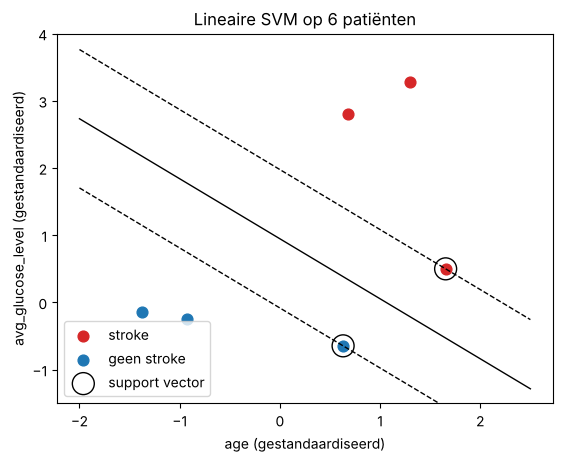

In [18]:
def plot_svm_example(model, x_data, y_data):
    """Tekent de 6 patiënten, het hypervlak en de randen van de marge."""
    x_line = np.linspace(-2, 2.5, 100)
    w1, w2 = model.coef_[0]
    for level, style in [(0, "-"), (1, "--"), (-1, "--")]:
        # f(x) = level omschrijven naar x2 = (level - b - w1 * x1) / w2
        x2 = (level - model.intercept_[0] - w1 * x_line) / w2
        plt.plot(x_line, x2, "k" + style, linewidth=1)
    for label, color, name in [(1, "tab:red", "stroke"),
                               (-1, "tab:blue", "geen stroke")]:
        mask = y_data == label
        plt.scatter(x_data[mask, 0], x_data[mask, 1], c=color, s=60,
                    label=name)
    sv = model.support_vectors_
    plt.scatter(sv[:, 0], sv[:, 1], s=250, facecolors="none",
                edgecolors="k", label="support vector")
    plt.xlabel("age (gestandaardiseerd)")
    plt.ylabel("avg_glucose_level (gestandaardiseerd)")
    plt.ylim(-1.5, 4)
    plt.legend()
    plt.title("Lineaire SVM op 6 patiënten")
    plt.show()


plot_svm_example(svm_small, x_small, y_small)

**Uitwerking met de hand**
De SVM vindt $w_1 = 0{,}87$ (leeftijd), $w_2 = 0{,}97$ (glucose) en
$b = -0{,}92$. Beide gewichten zijn positief. Een hogere leeftijd en een
hoger glucosegehalte duwen een patiënt dus naar de stroke-kant. Dat past bij
wat we in de EDA zagen.

*Patiënt 1* (71 jaar, glucose 241,77, gestandaardiseerd 1,30 en 3,28)

$$f(x) = 0{,}87 \cdot 1{,}30 + 0{,}97 \cdot 3{,}28 - 0{,}92 = 1{,}13 + 3{,}18 - 0{,}92 = 3{,}39$$

Positief en groter dan 1, dus stroke en ruim buiten de marge.

*Patiënt 4* (11 jaar, glucose 97,53, gestandaardiseerd −1,37 en −0,14)

$$f(x) = 0{,}87 \cdot (-1{,}37) + 0{,}97 \cdot (-0{,}14) - 0{,}92 = -1{,}19 - 0{,}14 - 0{,}92 = -2{,}25$$

Negatief, dus geen stroke. Ook deze ligt ruim buiten de marge.

*Patiënt 3* (79 jaar, glucose 124,57, gestandaardiseerd 1,65 en 0,50)

$$f(x) = 0{,}87 \cdot 1{,}65 + 0{,}97 \cdot 0{,}50 - 0{,}92 = 1{,}44 + 0{,}49 - 0{,}92 \approx 1{,}00$$

Deze patiënt ligt precies op de rand van de straat ($f(x) = +1$). Hetzelfde
geldt voor patiënt 5 aan de andere kant ($f(x) \approx -1$). Dit zijn dus de
twee support vectors, zoals ook in de figuur te zien is.

*De marge*

$$\lVert w \rVert = \sqrt{0{,}87^2 + 0{,}97^2} = \sqrt{1{,}698} = 1{,}30 \qquad \text{marge} = \frac{2}{1{,}30} = 1{,}54$$

*Een nieuwe patiënt* van 70 jaar met een glucose van 150. Gestandaardiseerd
is dat $(70 - 41{,}82) / 22{,}48 = 1{,}25$ en $(150 - 103{,}59) / 42{,}13 = 1{,}10$.

$$f(x) = 0{,}87 \cdot 1{,}25 + 0{,}97 \cdot 1{,}10 - 0{,}92 = 1{,}09 + 1{,}07 - 0{,}92 = 1{,}24$$

Het model voorspelt hier stroke.

### 3.5.2 Kernel en kernel trick
Een rechte grens is niet altijd genoeg. Soms liggen de groepen zo door
elkaar dat geen enkele rechte lijn ze goed scheidt. Het idee is dan om de
data om te zetten naar een ruimte met meer dimensies, waar de groepen wel
met een recht hypervlak te scheiden zijn. Die omzetting noemen we $\varphi(x)$.
Met twee features kan dat bijvoorbeeld zo

$$\varphi(x_1, x_2) = \left(x_1^2,\ \sqrt{2}\,x_1 x_2,\ x_2^2\right)$$

Het probleem is dat zo'n omzetting bij veel features heel groot wordt. Bij
de RBF-kernel heeft de nieuwe ruimte zelfs oneindig veel dimensies, dus die
kun je niet uitrekenen.

Hier komt de **kernel trick** om de hoek kijken (Radhakrishnan, 2023c). SVM heeft bij het trainen
en voorspellen alleen het inproduct tussen twee patiënten nodig, nooit de
losse coördinaten. De voorspelling kun je namelijk schrijven als

$$f(x) = \sum_{i \in \text{SV}} \alpha_i\, y_i\, K(x_i, x) + b$$

waarbij alleen de support vectors meetellen ($\alpha_i > 0$). Een **kernel**
$K(x, z)$ is een functie die het inproduct in de grote ruimte direct
uitrekent met de originele features, dus zonder $\varphi$ zelf te berekenen:

$$K(x, z) = \varphi(x) \cdot \varphi(z)$$

**Voorbeeld met de polynomiale kernel** $K(x, z) = (x \cdot z)^2$, met
patiënt 1 $x = (1{,}30;\ 3{,}28)$ en patiënt 4 $z = (-1{,}37;\ -0{,}14)$

*Via de kernel (de trick)*

$$x \cdot z = 1{,}30 \cdot (-1{,}37) + 3{,}28 \cdot (-0{,}14) = -2{,}24 \qquad K(x, z) = (-2{,}24)^2 = 5{,}02$$

*Via de omweg met* $\varphi$

$$\varphi(x) = (1{,}69;\ 6{,}03;\ 10{,}76) \qquad \varphi(z) = (1{,}88;\ 0{,}27;\ 0{,}02)$$

$$\varphi(x) \cdot \varphi(z) = 1{,}69 \cdot 1{,}88 + 6{,}03 \cdot 0{,}27 + 10{,}76 \cdot 0{,}02 = 5{,}02$$

Hetzelfde antwoord, maar via de kernel hoef je maar één inproduct in 2
dimensies uit te rekenen in plaats van eerst alles naar 3 dimensies om te
zetten. Bij veel features scheelt dat enorm veel rekenwerk.

**De RBF-kernel** gebruiken we ook in de tuning

$$K(x, z) = e^{-\gamma \lVert x - z \rVert^2}$$

Je kunt deze kernel zien als een maat voor hoe sterk twee patiënten op
elkaar lijken. Zijn ze gelijk, dan is $K = 1$. Liggen ze ver uit elkaar, dan
gaat $K$ naar 0. Met $\gamma = 0{,}5$ geldt

- patiënt 1 en 2 liggen dicht bij elkaar, $\lVert x - z \rVert^2 = 0{,}61$, dus $K = e^{-0{,}30} = 0{,}74$
- patiënt 1 en 4 liggen ver uit elkaar, $\lVert x - z \rVert^2 = 18{,}83$, dus $K = e^{-9{,}41} \approx 0{,}0001$

$\gamma$ bepaalt hoe ver de invloed van een patiënt reikt. Bij een grote
$\gamma$ tellen alleen hele dichtbije patiënten mee en wordt de grens erg
grillig. Dat geeft snel overfitting.

In [19]:
def poly_kernel(x, z):
    """Polynomiale kernel (x . z)^2."""
    return (x @ z) ** 2


def phi(x):
    """Expliciete omzetting naar 3 dimensies die bij de kernel hoort."""
    return np.array([x[0] ** 2, np.sqrt(2) * x[0] * x[1], x[1] ** 2])


def rbf_kernel(x, z, gamma=0.5):
    """RBF-kernel exp(-gamma * ||x - z||^2)."""
    return np.exp(-gamma * np.sum((x - z) ** 2))


p1, p2, p4 = x_small.round(2)[[0, 1, 3]]
print(f"Kernel trick (x.z)^2       : {poly_kernel(p1, p4):.3f}")
print(f"Omweg phi(x).phi(z)        : {phi(p1) @ phi(p4):.3f}")
print(f"RBF patiënt 1 en 2 (dichtbij): {rbf_kernel(p1, p2):.3f}")
print(f"RBF patiënt 1 en 4 (ver weg) : {rbf_kernel(p1, p4):.5f}")

Kernel trick (x.z)^2       : 5.018
Omweg phi(x).phi(z)        : 5.018
RBF patiënt 1 en 2 (dichtbij): 0.739
RBF patiënt 1 en 4 (ver weg) : 0.00008


### 3.5.3 De loss-functie
Je kunt de soft margin ook schrijven als één loss-functie. Daarin zit de
**hinge loss**

$$L(w, b) = \underbrace{\tfrac{1}{2}\lVert w \rVert^2}_{\text{regularisatie}} + C \sum_{i=1}^{n} \underbrace{\max\big(0,\ 1 - y_i\, f(x_i)\big)}_{\text{hinge loss}}$$

De hinge loss per patiënt hangt af van $y_i \cdot f(x_i)$

- $y \cdot f(x) \ge 1$: goed voorspeld en buiten de marge. Loss is 0.
- $0 < y \cdot f(x) < 1$: goed voorspeld, maar binnen de marge. Kleine loss.
- $y \cdot f(x) < 0$: aan de verkeerde kant van het hypervlak. Loss is
  groter dan 1 en groeit lineair met de afstand.

**Voorbeeld met het rekenvoorbeeld**
- Patiënt 4 heeft $y = -1$ en $f(x) = -2{,}25$. Dan is $y \cdot f(x) = 2{,}25$
  en de loss $\max(0,\ 1 - 2{,}25) = 0$.
- Patiënt 3 ligt precies op de rand, $y \cdot f(x) = 1$, dus de loss is 0.
- Stel een stroke-patiënt krijgt $f(x) = 0{,}4$. Die ligt goed maar binnen de
  marge, loss $= 1 - 0{,}4 = 0{,}6$.
- Krijgt diezelfde patiënt $f(x) = -0{,}5$, dan ligt hij aan de verkeerde
  kant. Loss $= 1 - (-0{,}5) = 1{,}5$.

Het verschil met de log loss van Logistic Regression is dat de hinge loss
echt 0 wordt zodra een patiënt veilig aan de goede kant ligt. Die patiënten
doen dan niet meer mee, en daarom bepalen alleen de support vectors de
grens. Een SVM geeft ook geen kans maar alleen een afstand $f(x)$ tot het
hypervlak. Dat is belangrijk voor onze threshold-techniek, zie hieronder.

### 3.5.4 Regularisatie
Bij SVM zit regularisatie al standaard in de loss-functie. Er zijn twee
vormen.

*L2-regularisatie (standaard)*

$$\tfrac{1}{2}\lVert w \rVert^2 = \tfrac{1}{2} \sum_{j=1}^{n} w_j^2$$

Dit is de term die ook de marge bepaalt. Kleine gewichten geven een brede
marge en dus een eenvoudiger model. Net als bij Logistic Regression worden
alle gewichten kleiner, maar bijna nooit precies 0.

*L1-regularisatie (alleen bij een lineaire SVM)*

$$\lVert w \rVert_1 = \sum_{j=1}^{n} |w_j|$$

Met L1 worden de gewichten van onbelangrijke features precies 0. Het model
doet dan zelf feature selection. Dit kan alleen bij een lineaire SVM
(`LinearSVC` met `penalty="l1"`), want bij een kernel-SVM bestaan de
gewichten $w$ niet los. Die zitten verstopt in de kernel.

*De rol van C*
$C$ bepaalt de balans tussen een brede marge en weinig fouten. Je kunt de
loss ook schrijven als $\lambda \lVert w \rVert^2 + \frac{1}{n}\sum \text{hinge}$,
met $C \sim 1/\lambda$. Net als bij Logistic Regression werkt $C$ dus
andersom.

- Bij een **grote C** tellen fouten zwaar. De marge wordt smal en het model volgt
  de trainingsdata heel precies. Risico op **overfitting**.
- Bij een **kleine C** tellen fouten weinig. De marge wordt breed en het model
  accepteert meer fouten. Risico op **underfitting**.

Bij de RBF-kernel werkt $\gamma$ op een vergelijkbare manier. Een grote
$\gamma$ maakt de grens grilliger (overfitting), een kleine $\gamma$ maakt
hem gladder (underfitting).

Hieronder laten we het verschil tussen L1 en L2 zien met een lineaire SVM
en een vrij kleine $C$ (dus sterke regularisatie).

In [20]:
def linear_svm_weights(penalty, c_value=0.01):
    """Traint een lineaire SVM en geeft de gewichten per feature terug."""
    model = make_pipeline(StandardScaler(),
                          LinearSVC(penalty=penalty, C=c_value, dual=False,
                                    max_iter=5000))
    model.fit(X, y)
    return pd.Series(model[-1].coef_[0], index=X.columns)


weights = pd.DataFrame({"L1": linear_svm_weights("l1"),
                        "L2": linear_svm_weights("l2")}).round(4)
display(weights)
print("Gewichten precies 0 bij L1:", (weights["L1"] == 0).sum())
print("Gewichten precies 0 bij L2:", (weights["L2"] == 0).sum())

,L1,L2
age,0.0530,0.0672
hypertension,0.0085,0.0096
heart_disease,0.0134,0.0137
avg_glucose_level,0.0092,0.0110
bmi,-0.0046,-0.0074
gender_Male,0.0000,0.0010
ever_married_Yes,-0.0062,-0.0130
work_type_Govt_job,-0.0010,-0.0072
work_type_Never_worked,0.0000,-0.0009
work_type_Private,0.0000,-0.0071


Gewichten precies 0 bij L1: 8
Gewichten precies 0 bij L2: 0


Bij L1 zijn 8 van de 16 gewichten precies 0 geworden, waaronder
`gender_Male`, `Residence_type_Urban`, `work_type_children` en alle
rookkolommen. Het model gebruikt die features dus helemaal niet meer. Bij L2
is geen enkel gewicht 0, ze zijn alleen allemaal klein. In beide gevallen
heeft `age` veruit het grootste gewicht. Bij L1 volgen daarna
`heart_disease`, `avg_glucose_level` en `hypertension`, precies de features
die in de EDA het sterkst met stroke samenhingen. Bij L2 krijgt ook
`work_type_children` nog een redelijk gewicht. Die feature hangt sterk samen
met leeftijd. L2 verdeelt het gewicht over features die op elkaar lijken,
terwijl L1 er liever één kiest.

### 3.5.5 Hyperparameter tuning
We tunen de volgende hyperparameters
- `kernel` (linear of rbf)
- `C` (de sterkte van de regularisatie)
- `gamma` (alleen bij de rbf-kernel)

SVM is een stuk trager dan de vorige modellen, omdat de rekentijd ongeveer
kwadratisch groeit met het aantal patiënten. Daarom zetten we SMOTE hier vast
op een `sampling_strategy` van 0,3. Dat was ook de beste waarde bij KNN.

Onze `ModelTuner` zoekt de threshold op de kans uit `predict_proba`. Een SVM
geeft geen kans maar een afstand tot het hypervlak (`decision_function`). Je
kunt met `probability=True` wel een kans laten schatten, maar dan traint
scikit-learn intern nog eens 5 extra modellen en dat is hier veel te traag.
Daarom maken we een subklasse die de threshold op de afstand zoekt. Als
mogelijke thresholds nemen we de percentielen 50 tot en met 99,5 van alle
afstanden. Zo proberen we steeds een ander deel van de patiënten als
stroke te markeren.

In [21]:
class SVMTuner(ModelTuner):
    """ModelTuner voor modellen zonder predict_proba, zoals de SVM.

    De threshold wordt gezocht op de afstand tot het hypervlak
    (decision_function) in plaats van op een kans. Daarnaast kan de grid
    een lijst van dicts zijn, zodat gamma alleen bij de rbf-kernel hoort.
    """

    def __init__(self, name, model, params, scale=True):
        super().__init__(name, model, {}, scale)
        self.params = [{k if "__" in k else f"model__{k}": v
                        for k, v in grid.items()} for grid in params]

    def tune_threshold(self):
        scores = cross_val_predict(self.grid.best_estimator_, X, y, cv=CV,
                                   method="decision_function", n_jobs=-1)
        # thresholds zijn de percentielen 50 t/m 99,5 van de afstanden
        thresholds = np.percentile(scores, np.arange(50, 100, 0.5))
        f1_scores = [f1_score(y, scores >= t) for t in thresholds]
        self.threshold = float(thresholds[np.argmax(f1_scores)])
        self.f1 = max(f1_scores)
        print(f"Beste threshold (afstand): {self.threshold:.2f} "
              f"-> F1: {self.f1:.3f}")
        ConfusionMatrixDisplay.from_predictions(y, scores >= self.threshold)
        plt.show()

    def submit(self):
        scores = self.grid.best_estimator_.decision_function(test.df)
        pred = (scores >= self.threshold).astype(int)
        file = f"submission_{self.name}.csv"
        pd.DataFrame({"id": test.ids, "stroke": pred}).to_csv(file,
                                                              index=False)
        RESULTS[self.name] = {"F1 notebook": round(self.f1, 3),
                              "threshold": round(self.threshold, 2),
                              "hyperparameters": self.grid.best_params_}
        print(f"Opgeslagen: {file} ({pred.sum()} keer stroke voorspeld)")

Beste hyperparameters: {'model__C': 1, 'model__kernel': 'linear', 'smote__sampling_strategy': 0.3}
F1 bij threshold 0,5: 0.139


Beste threshold (afstand): 0.33 -> F1: 0.149


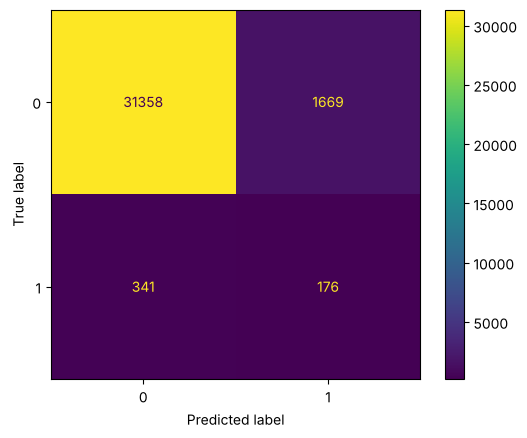

Opgeslagen: submission_svm.csv (467 keer stroke voorspeld)


In [22]:
svm = SVMTuner("svm", SVC(cache_size=1000),
               [{"kernel": ["linear"], "C": [0.1, 1],
                 "smote__sampling_strategy": [0.3]},
                {"kernel": ["rbf"], "C": [0.1, 1, 10],
                 "gamma": ["scale", 0.05],
                 "smote__sampling_strategy": [0.3]}])
svm.run()

**Resultaat SVM**
De beste SVM gebruikt een **lineaire kernel met C = 1** en SMOTE met een
`sampling_strategy` van 0,3. Bij de standaardgrens $f(x) = 0$ is de F1-score
0,139. In de uitvoer staat dit als "threshold 0,5", omdat de `ModelTuner`
die tekst voor alle modellen gebruikt. Met de beste threshold op de afstand
(0,33) stijgt de F1-score naar **0,149**. Dat is tot nu toe de hoogste
score. Op de testset voorspelt het model 467 keer stroke.

Dat de lineaire kernel wint van de rbf-kernel zegt iets over de data. Het
verband tussen de features en stroke is grotendeels "recht". Hoe ouder en
hoe hoger de glucose, hoe groter het risico. De extra flexibiliteit van de
rbf-kernel helpt hier niet en zorgt vooral voor het leren van ruis. C = 1 is
de grootste waarde die we bij de lineaire kernel hebben geprobeerd. Een
grotere C maakt de lineaire SVM erg traag, daarom hebben we die niet
meegenomen.

Een nadeel is de rekentijd. De SVM was veruit het traagste model om te
tunen.

### 3.5.6 Voor- en nadelen
**Voordelen**
- De grootste marge maakt het model robuust. Alleen de support vectors tellen
  mee, dus patiënten ver van de grens hebben geen invloed.
- Met een kernel kan het model ook niet-lineaire grenzen leren, zonder dat we
  zelf nieuwe features hoeven te maken.
- Werkt goed als er veel features zijn.
- Met een lineaire kernel zijn de gewichten nog redelijk uit te leggen.

**Nadelen**
- Traag op grote datasets, omdat de rekentijd ongeveer kwadratisch groeit met
  het aantal patiënten. Bij ons was het veruit het traagste model.
- Geeft geen kans maar alleen een afstand. Een kans laten schatten met
  `probability=True` maakt het model nog trager.
- Gevoelig voor de schaal van de data, dus standaardiseren is verplicht.
- C en gamma moeten goed getuned worden. Met verkeerde waarden krijg je snel
  overfitting of underfitting.
- Een SVM met een rbf-kernel is moeilijk uit te leggen aan een arts.

## 3.6 Decision Tree

**Hoe werkt het?**
Een decision tree is een boom met ja/nee-vragen, een soort stroomschema
(Breiman et al., 1984).
Bovenaan staat de root node met alle patiënten. Het model zoekt de feature
en de grenswaarde die de groep het best splitst, bijvoorbeeld
"age ≤ 67,5?". Zo ontstaan twee takken. In iedere tak herhaalt het model dit
weer, totdat een stopcriterium is bereikt. De laatste knopen heten
bladeren (leaves). Het aandeel stroke-patiënten in een blad is de
voorspelde kans voor iedere nieuwe patiënt die daar terechtkomt.

Een nieuwe patiënt loopt de boom van boven naar beneden af en komt in één
blad uit. Je kunt dus precies volgen waarom het model iets voorspelt. Dat
maakt een beslisboom goed uit te leggen aan een arts. Omdat de boom steeds
naar één feature tegelijk kijkt, maakt de schaal van de data niet uit.
Standaardiseren is hier dus niet nodig (`scale=False`).

### 3.6.1 Splitcriteria
Bij iedere split kiest de boom de vraag die de groepen het "zuiverst" maakt.
Zuiver betekent dat er in een knoop bijna alleen maar patiënten van één
klasse zitten. Dat meten we met een impurity-maat. Scikit-learn kent er
twee (`log_loss` is in scikit-learn hetzelfde als entropy).

*Gini-index*

$$G = 1 - \sum_{k} p_k^2$$

*Entropy*

$$H = -\sum_{k} p_k \log_2(p_k)$$

$p_k$ is het aandeel patiënten van klasse $k$ in de knoop. Bij een zuivere
knoop zijn beide 0. Bij een 50/50-verdeling zijn ze maximaal (Gini 0,5 en
entropy 1). De boom kiest de split met de grootste daling in impurity, de
**information gain**

$$\text{Gain} = I(\text{ouder}) - \frac{n_L}{n}\, I(\text{links}) - \frac{n_R}{n}\, I(\text{rechts})$$

Hierbij is $I$ de Gini of de entropy, en zijn $n_L$ en $n_R$ het aantal
patiënten in de linker en rechter tak. De boom kiest per stap de beste
split. Hij kijkt dus niet vooruit naar latere splits (greedy).

**Voorbeeld uit onze data, split op hypertension**

In [23]:
def gini(labels):
    """Gini-index van een groep labels."""
    p = labels.mean()
    return 1 - p ** 2 - (1 - p) ** 2


def entropy(labels):
    """Entropy (log2) van een groep labels."""
    p = labels.mean()
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


def split_gain(feature, impurity):
    """Berekent de information gain van een split op een 0/1-feature."""
    left, right = y[X[feature] == 0], y[X[feature] == 1]
    weighted = (len(left) * impurity(left)
                + len(right) * impurity(right)) / len(y)
    print(f"{impurity.__name__:8} ouder {impurity(y):.4f} | "
          f"links ({len(left)}, {left.sum()} stroke) {impurity(left):.4f} | "
          f"rechts ({len(right)}, {right.sum()} stroke) "
          f"{impurity(right):.4f} | gain {impurity(y) - weighted:.4f}")


split_gain("hypertension", gini)
split_gain("hypertension", entropy)

gini     ouder 0.0304 | links (30587, 373 stroke) 0.0241 | rechts (2957, 144 stroke) 0.0927 | gain 0.0002
entropy  ouder 0.1148 | links (30587, 373 stroke) 0.0950 | rechts (2957, 144 stroke) 0.2808 | gain 0.0034


In de hele trainingsset zitten 33.544 patiënten, waarvan 517 met stroke
($p = 0{,}0154$). De Gini van de root node is dan

$$G = 1 - 0{,}0154^2 - 0{,}9846^2 = 0{,}0304$$

Na de split op `hypertension` krijgen we
- links (geen hypertensie) 30.587 patiënten, 373 stroke, Gini 0,0241
- rechts (wel hypertensie) 2.957 patiënten, 144 stroke, Gini 0,0927

$$\text{Gain} = 0{,}0304 - \tfrac{30.587}{33.544} \cdot 0{,}0241 - \tfrac{2.957}{33.544} \cdot 0{,}0927 = 0{,}0304 - 0{,}0220 - 0{,}0082 = 0{,}0002$$

Met entropy krijgen we hetzelfde beeld. De entropy van de ouder is 0,1148,
links 0,0950 en rechts 0,2808, wat een gain van 0,0034 oplevert.

De rechter groep is duidelijk minder zuiver, want daar zit relatief veel
meer stroke. De split maakt dus wel onderscheid. Toch is de gain heel klein,
omdat in beide groepen bijna iedereen géén stroke heeft. Dat is precies het
probleem van ongebalanceerde data. Na SMOTE zijn de groepen meer in balans
en worden de verschillen tussen splits groter. In de praktijk kiezen Gini
en entropy meestal dezelfde splits. Gini is iets sneller, omdat er geen
logaritme in zit.

### 3.6.2 Pruning
Als je een beslisboom niet tegenhoudt, blijft hij splitsen tot ieder blad
helemaal zuiver is. In het uiterste geval krijgt iedere patiënt zijn eigen
blad. De boom heeft dan de trainingsdata uit zijn hoofd geleerd, inclusief
alle ruis. Op nieuwe patiënten werkt hij slecht. Dat is **overfitting**.

**Pruning** betekent letterlijk snoeien. Je maakt de boom kleiner, zodat hij
alleen de belangrijke patronen overhoudt. Er zijn twee vormen en we passen
ze allebei toe.

*Pre-pruning (vooraf)* stopt de groei van de boom eerder
- `max_depth` bepaalt hoe diep de boom maximaal mag worden
- `min_samples_leaf` bepaalt hoeveel patiënten er minstens in een blad
  moeten zitten

*Post-pruning (achteraf)* laat de boom eerst helemaal groeien en knipt daarna
de takken weg die weinig toevoegen. In scikit-learn heet dit cost complexity
pruning (Pedregosa et al., 2011), met de hyperparameter `ccp_alpha`

$$R_\alpha(T) = R(T) + \alpha \cdot |T|$$

$R(T)$ is de totale impurity van de bladeren en $|T|$ het aantal bladeren.
Ieder extra blad kost dus een boete $\alpha$. Een tak blijft alleen staan als
hij de impurity meer verlaagt dan hij aan boete kost. Hoe groter $\alpha$,
hoe kleiner de boom.

**Pruning en under- of overfitting**
- Geen of weinig pruning geeft een grote boom die de trainingsdata volgt.
  Dat leidt tot **overfitting**.
- Te veel pruning geeft een hele kleine boom, bijvoorbeeld met maar één
  split. Die mist echte patronen en dat is **underfitting**.

Met hyperparameter tuning zoeken we de boom die daar precies tussenin zit.

### 3.6.3 Hyperparameter tuning
We tunen `criterion` (gini of entropy), de pre-pruning (`max_depth` en
`min_samples_leaf`), de post-pruning (`ccp_alpha`) en de hoeveelheid SMOTE.

Beste hyperparameters: {'model__ccp_alpha': 0.0, 'model__criterion': 'entropy', 'model__max_depth': 4, 'model__min_samples_leaf': 1, 'smote__sampling_strategy': 0.3}
F1 bij threshold 0,5: 0.100


Beste threshold: 0.51 -> F1: 0.106


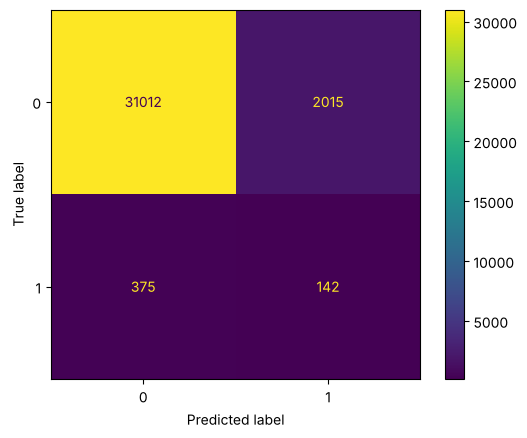

Opgeslagen: submission_tree.csv (552 keer stroke voorspeld)


In [24]:
tree = ModelTuner("tree", DecisionTreeClassifier(random_state=42),
                  {"criterion": ["gini", "entropy"],
                   "max_depth": [4, 6, 8, None],
                   "min_samples_leaf": [1, 20, 50],
                   "ccp_alpha": [0.0, 0.0001, 0.001],
                   "smote__sampling_strategy": [0.1, 0.3]},
                  scale=False)
tree.run()

**Interpretatie van de boom**
Hieronder staan de bovenste lagen van de beste boom en de feature importance.
De feature importance laat zien hoeveel iedere feature in totaal heeft
bijgedragen aan het verlagen van de impurity.

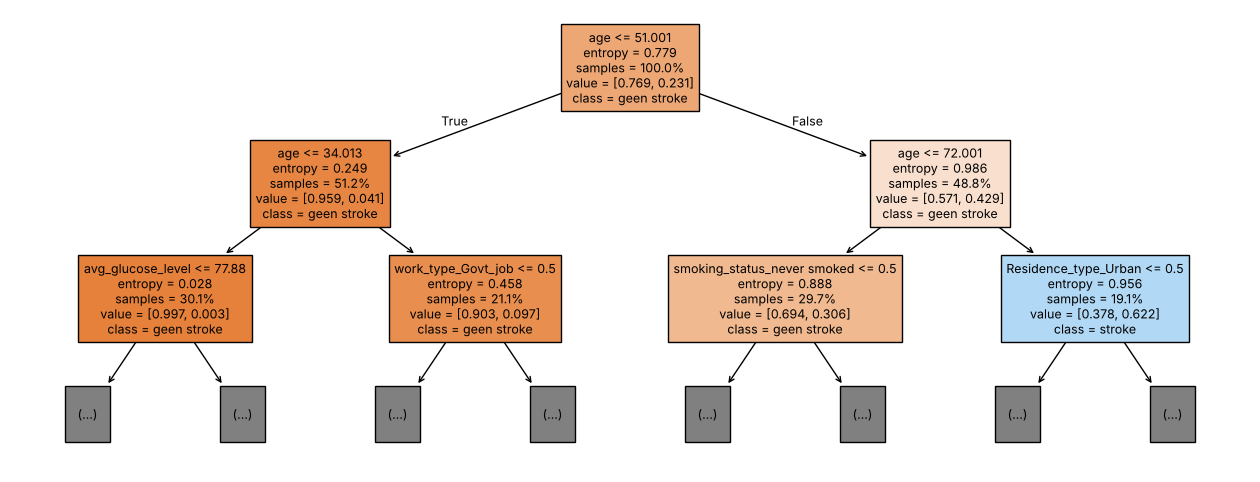

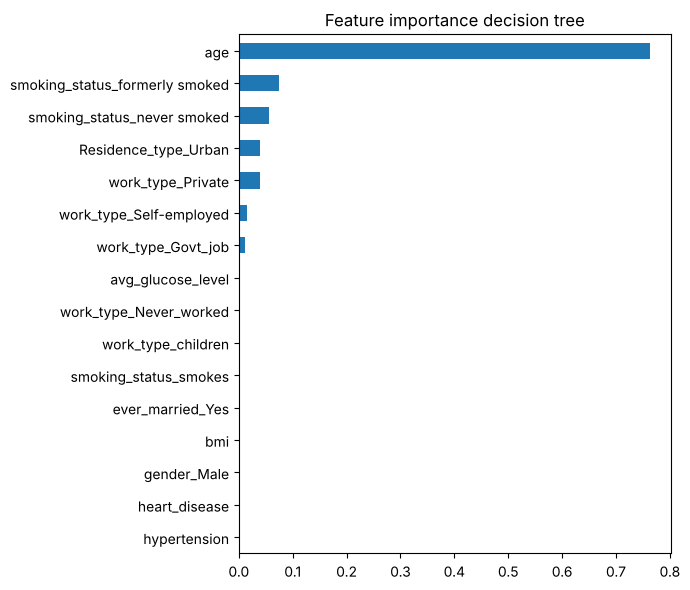

Aantal bladeren: 16 | diepte: 4


In [25]:
def show_tree(tuner, depth=2):
    """Toont de bovenste lagen van de boom en de feature importance."""
    model = tuner.grid.best_estimator_.named_steps["model"]
    plt.figure(figsize=(16, 6))
    plot_tree(model, max_depth=depth, feature_names=list(X.columns),
              class_names=["geen stroke", "stroke"], filled=True,
              proportion=True, fontsize=9)
    plt.show()
    importance = pd.Series(model.feature_importances_, index=X.columns)
    importance.sort_values().plot.barh(figsize=(7, 6))
    plt.title("Feature importance decision tree")
    plt.tight_layout()
    plt.show()
    print("Aantal bladeren:", model.get_n_leaves(),
          "| diepte:", model.get_depth())


show_tree(tree)

**Resultaat Decision Tree**
De beste boom gebruikt **entropy**, een **max_depth van 4**,
`min_samples_leaf` = 1, `ccp_alpha` = 0 en SMOTE 0,3. Met de beste threshold
(0,51) is de F1-score **0,106**. De boom heeft 16 bladeren.

*Welke pruning werkte?* De pre-pruning via `max_depth` deed hier al het
werk. De kleinste diepte uit de grid (4) won, dus diepere bomen gingen
overfitten. Omdat de boom al zo klein is, voegen `min_samples_leaf` en
`ccp_alpha` niets meer toe. Diepte 4 is wel de kleinste waarde die we
geprobeerd hebben. Misschien werkt een nog ondiepere boom zelfs beter.

*Interpretatie.* De boom splitst eerst op leeftijd (51 jaar), daarna nog een
keer op leeftijd (34 en 72 jaar). In de groep boven de 72 jaar is de
meerderheid stroke. Let op, de percentages in de figuur zijn na SMOTE. Daarom
is 23% van de patiënten in de root node stroke en niet 1,5%. Volgens de
feature importance doet `age` ongeveer 76% van het werk.

Opvallend is dat de boom bijna niets doet met `avg_glucose_level`,
`hypertension` en `heart_disease`, maar wel splitst op roken en
`Residence_type_Urban`. Uit de EDA bleek juist dat woontype geen verband
heeft met stroke. Dit komt waarschijnlijk door SMOTE. SMOTE maakt nieuwe
patiënten door tussen twee bestaande patiënten in te gaan zitten, ook bij
de 0/1-kolommen. Zo ontstaan waarden als 0,4 voor `Residence_type_Urban`,
die in het echt niet bestaan. Een boom kan precies op zulke waarden splitsen
(≤ 0,5) en leert dan patronen van nep-patiënten. Dat verklaart ook de lage
score.

## 3.7 Ensembles

Een ensemble combineert veel modellen tot één model. Bij Random Forest,
Gradient Boosting en XGBoost zijn dat allemaal beslisbomen. Het verschil zit
in hoe die bomen gemaakt en gecombineerd worden. Daarvoor zijn er twee
technieken, bagging en boosting (Radhakrishnan, 2023a).

### 3.7.1 Random Forest (bagging)
**Bagging** staat voor bootstrap aggregation.
- Bij *bootstrap* krijgt iedere boom een eigen steekproef uit de trainingsdata.
  Die steekproef is even groot als de trainingsdata, maar wordt getrokken
  met teruglegging. Sommige patiënten komen er dus meerdere keren in voor en
  andere helemaal niet (ongeveer 37%).
- Bij *aggregation* worden de voorspellingen van alle bomen samengevoegd. Bij
  Random Forest is de kans het gemiddelde van de kansen van alle bomen.

Random Forest (Breiman, 2001) voegt daar nog iets aan toe. Bij iedere split mag een boom
maar uit een willekeurig deel van de features kiezen (`max_features`).
Daardoor gaan de bomen nog meer van elkaar verschillen.

Een losse diepe boom overfit snel, want hij heeft een hoge variantie. Omdat
iedere boom op andere data en andere features is getraind, maken ze ook
verschillende fouten. Door te middelen vallen die fouten voor een groot deel
tegen elkaar weg. Het bos is daardoor stabieler dan één boom.

De bomen zijn helemaal onafhankelijk van elkaar. Ze kunnen dus **parallel**
getraind worden, verdeeld over meerdere processorkernen (`n_jobs`). Random
Forest heeft daardoor relatief **weinig trainingstijd** nodig.

### 3.7.2 Gradient Boosting (boosting)
Bij **boosting** worden de bomen niet los van elkaar gemaakt, maar na
elkaar. Iedere nieuwe boom probeert de fouten van de vorige bomen te
herstellen (Friedman, 2001). Het werkt zo.
1. Begin met een simpele voorspelling, bijvoorbeeld het gemiddelde
   stroke-percentage.
2. Bereken per patiënt hoe fout het model nog zit. Bij classificatie is dat
   de gradient van de log loss, ongeveer $y_i - p_i$.
3. Train een kleine boom (bijvoorbeeld diepte 3) die precies die fouten
   voorspelt.
4. Tel die boom met een kleine stap op bij het model

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

$h_m$ is de nieuwe boom en $\eta$ de learning rate. Daarna begint het weer
bij stap 2. Een enkele kleine boom is een zwak model (weak learner), maar
samen worden ze sterk. Bagging verlaagt vooral de variantie, boosting
verlaagt vooral de bias.

Omdat boom $m$ de fouten van boom $m - 1$ nodig heeft, moet alles
**sequential** (na elkaar). Je kunt de bomen niet tegelijk trainen. Gradient
Boosting van scikit-learn heeft daardoor relatief **veel trainingstijd**
nodig. Te veel bomen of een te hoge learning rate geeft overfitting.

### 3.7.3 XGBoost
XGBoost (Extreme Gradient Boosting) gebruikt hetzelfde boosting-idee
(Chen & Guestrin, 2016), met een
paar verbeteringen.
- Er zit regularisatie in de loss-functie zelf

$$\text{Obj} = \sum_{i=1}^{n} L(y_i, \hat{y}_i) + \sum_{m} \Omega(h_m) \qquad \Omega(h) = \gamma\, T + \tfrac{1}{2}\lambda \sum_{j=1}^{T} w_j^2$$

  Hierbij is $T$ het aantal bladeren en $w_j$ de waarde in een blad. Grote
  bomen en extreme bladwaarden worden dus bestraft. Dat remt overfitting af.
- XGBoost gebruikt naast de eerste ook de tweede afgeleide van de loss.
  Daardoor zet het betere stappen.
- De bomen worden nog steeds **sequential** gemaakt, maar het bouwen van
  één boom gebeurt **parallel**. Het zoeken naar de beste split wordt over
  de features verdeeld en werkt met histogrammen in plaats van alle losse
  waarden.

XGBoost is daardoor meestal veel sneller dan Gradient Boosting van
scikit-learn, ook al is het een boosting-methode.

### 3.7.4 Hyperparameter tuning
- Bij Random Forest `max_depth` en `min_samples_leaf` (pre-pruning per boom),
  met 200 bomen.
- Bij Gradient Boosting en XGBoost `n_estimators` (aantal bomen),
  `learning_rate` en `max_depth`.
- Bij alle drie ook de hoeveelheid SMOTE.

Binnen de grid search zetten we `n_jobs` van de modellen zelf op 1, omdat
`GridSearchCV` de folds al parallel draait. Bij het meten van de
trainingstijd hieronder gebruiken Random Forest en XGBoost wel alle kernen.

Beste hyperparameters: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'smote__sampling_strategy': 0.3}
F1 bij threshold 0,5: 0.078


Beste threshold: 0.34 -> F1: 0.097


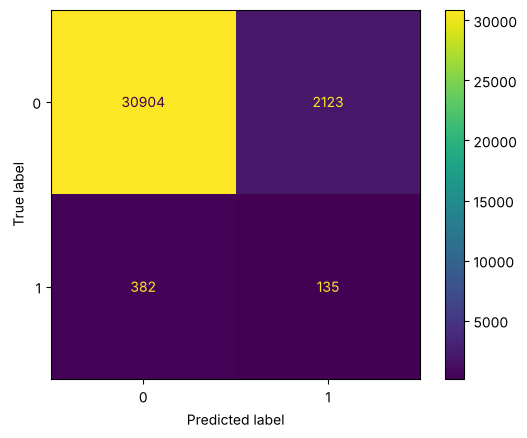

Opgeslagen: submission_rf.csv (524 keer stroke voorspeld)


In [26]:
rf = ModelTuner("rf", RandomForestClassifier(n_estimators=200,
                                             random_state=42),
                {"max_depth": [8, 12, None],
                 "min_samples_leaf": [1, 10],
                 "smote__sampling_strategy": [0.1, 0.3]},
                scale=False)
rf.run()

Beste hyperparameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100, 'smote__sampling_strategy': 0.3}
F1 bij threshold 0,5: 0.070


Beste threshold: 0.36 -> F1: 0.119


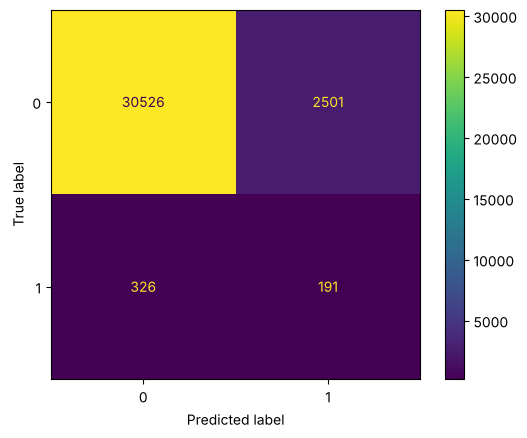

Opgeslagen: submission_gb.csv (635 keer stroke voorspeld)


In [27]:
gb = ModelTuner("gb", GradientBoostingClassifier(random_state=42),
                {"n_estimators": [100, 200],
                 "learning_rate": [0.05, 0.1],
                 "max_depth": [2, 3],
                 "smote__sampling_strategy": [0.1, 0.3]},
                scale=False)
gb.run()

Beste hyperparameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'smote__sampling_strategy': 0.3}
F1 bij threshold 0,5: 0.066


Beste threshold: 0.28 -> F1: 0.091


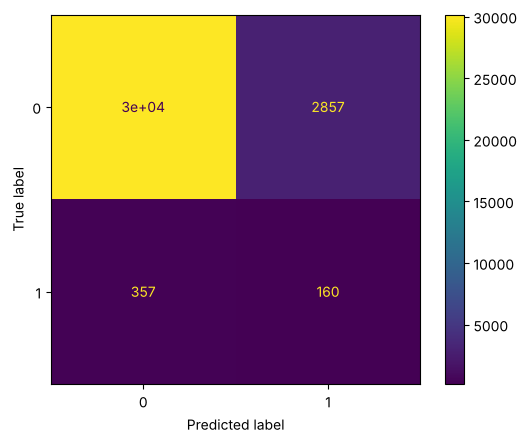

Opgeslagen: submission_xgb.csv (711 keer stroke voorspeld)


In [28]:
xgb = ModelTuner("xgb", XGBClassifier(eval_metric="logloss",
                                      tree_method="hist", n_jobs=1,
                                      random_state=42),
                 {"n_estimators": [200, 400],
                  "learning_rate": [0.05, 0.1],
                  "max_depth": [3, 5],
                  "smote__sampling_strategy": [0.1, 0.3]},
                 scale=False)
xgb.run()

### 3.7.5 Trainingstijd
We trainen het beste model van ieder ensemble één keer opnieuw op alle
trainingsdata en meten hoe lang dat duurt. Random Forest en XGBoost mogen
daarbij alle processorkernen gebruiken.

In [29]:
def measure_fit_time(tuner):
    """Meet de trainingstijd van het beste model van een tuner."""
    pipe = clone(tuner.grid.best_estimator_)
    if "n_jobs" in pipe.named_steps["model"].get_params():
        pipe.set_params(model__n_jobs=-1)  # parallel waar het kan
    start = time.perf_counter()
    pipe.fit(X, y)
    seconds = round(time.perf_counter() - start, 1)
    RESULTS[tuner.name]["fit tijd (s)"] = seconds
    return seconds


for tuner in [rf, gb, xgb]:
    measure_fit_time(tuner)
display(pd.DataFrame(RESULTS).T.loc[["rf", "gb", "xgb"],
                                    ["F1 notebook", "fit tijd (s)",
                                     "hyperparameters"]])

,F1 notebook,fit tijd (s),hyperparameters
rf,0.097,2.8,"{'model__max_depth': 8, 'model__min_samples_le..."
gb,0.119,3.4,"{'model__learning_rate': 0.05, 'model__max_dep..."
xgb,0.091,0.3,"{'model__learning_rate': 0.05, 'model__max_dep..."


**Resultaten ensembles**

| Ensemble | Beste hyperparameters | Threshold | F1 notebook |
|---|---|---|---|
| Random Forest | max_depth 8, min_samples_leaf 1, SMOTE 0,3 | 0,34 | 0,097 |
| Gradient Boosting | 100 bomen, learning_rate 0,05, max_depth 2, SMOTE 0,3 | 0,36 | 0,119 |
| XGBoost | 200 bomen, learning_rate 0,05, max_depth 3, SMOTE 0,3 | 0,28 | 0,091 |

Opvallend is dat de ensembles lager scoren dan de lineaire modellen, en
Random Forest en XGBoost zelfs lager dan KNN. Bij alle drie wonnen de meest
eenvoudige instellingen uit de grid. Random Forest koos de kleinste diepte,
Gradient Boosting en XGBoost kozen zelfs bij alle drie de hyperparameters de
kleinste waarde (minste bomen, laagste learning rate, kleinste diepte). Dat wijst op
overfitting. De bomen leren de nep-patiënten van SMOTE te goed, net als bij
de losse decision tree. Daarbij is het signaal in deze data vrij eenvoudig
(vooral leeftijd en glucose). De kracht van ensembles, het vinden van
ingewikkelde verbanden, komt hier dus niet goed tot zijn recht.

**Trainingstijd**
In onze run kostte Gradient Boosting de meeste tijd (3,4 s), daarna Random
Forest (2,8 s) en XGBoost was het snelst (0,3 s). Gradient Boosting is het
traagst, terwijl het maar 100 kleine bomen maakt en Random Forest 200 diepe
bomen. Dat komt doordat boosting **sequential** werkt, terwijl de bomen van
Random Forest **parallel** gemaakt worden. XGBoost is ook sequential, maar
bouwt iedere boom parallel en met histogrammen, en is daardoor het snelst.
De exacte tijden hangen af van de computer, maar de volgorde is wat we op
basis van de theorie verwachten.

## 3.8 Zelf samengesteld ensemble

**Hoe werkt een ensemble?**
Bij een ensemble laten we meerdere modellen dezelfde patiënt beoordelen
(Radhakrishnan, 2023a) en
combineren we hun antwoorden. Je kunt het vergelijken met een second
opinion. Eén arts kan zich vergissen, maar als drie artsen met een andere
achtergrond het eens zijn, is de kans op een fout kleiner. Dat werkt alleen
als de modellen allemaal redelijk goed zijn en vooral verschillende fouten
maken.

**Hard of soft voting?**
- Bij *hard voting* geeft ieder model een stem, 0 of 1. De meerderheid wint.
- Bij *soft voting* geeft ieder model een kans. Het ensemble neemt het
  (gewogen) gemiddelde

$$p_{\text{ensemble}} = \frac{\sum_{m} w_m\, p_m}{\sum_{m} w_m}$$

We kiezen voor **soft voting**, om drie redenen.
1. Het model gebruikt hoe zeker ieder model is. Een model dat 0,9 zegt telt
   zwaarder dan een model dat twijfelt met 0,51. Bij hard voting zijn dat
   allebei gewoon een "ja".
2. We hebben een kans nodig om de threshold te kunnen tunen. Dat is een van
   onze twee technieken tegen de ongebalanceerde data. Hard voting geeft
   alleen 0 of 1.
3. Met maar 1,5% stroke durven losse modellen niet snel "stroke" te zeggen.
   Bij hard voting moeten er dan ook nog twee van de drie tegelijk "ja"
   zeggen, waardoor het ensemble nog minder stroke-patiënten vindt.

**Keuze van de modellen**
We combineren Logistic Regression, Random Forest en XGBoost.
- *Logistic Regression* is een lineair model en kijkt dus op een heel
  andere manier naar de data dan bomen. Het is stabiel en goed uit te leggen.
- *Random Forest* is een bagging-ensemble. Het vangt niet-lineaire verbanden
  en heeft een lage variantie.
- *XGBoost* is een boosting-ensemble. Het verlaagt vooral de bias en is vaak
  het sterkste losse model.

Zo hebben we drie verschillende soorten modellen die verschillende fouten
maken. De andere modellen laten we bewust weg. De SVM heeft geen
`predict_proba` (en met `probability=True` is hij veel te traag), KNN is traag
bij het voorspellen en moet alle trainingsdata bewaren, de losse beslisboom zit eigenlijk al
in Random Forest, en Gradient Boosting lijkt sterk op XGBoost maar is trager.

**Hyperparameters**
Ieder model krijgt de beste hyperparameters uit zijn eigen tuning. Alles
opnieuw tegelijk tunen kost veel te veel tijd. Voor het ensemble zelf tunen
we de gewichten $w_m$ van de drie modellen en de hoeveelheid SMOTE.

Beste hyperparameters: {'model__weights': [2, 1, 1], 'smote__sampling_strategy': 0.3}
F1 bij threshold 0,5: 0.136


Beste threshold: 0.49 -> F1: 0.138


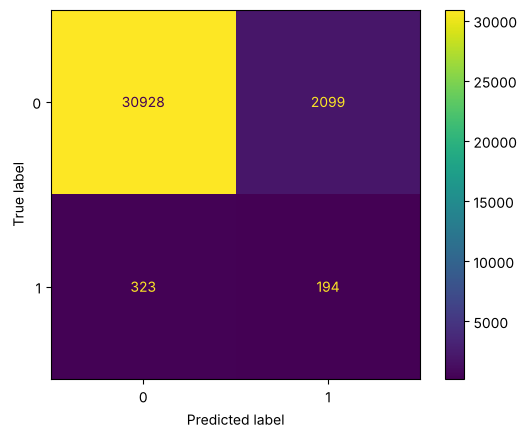

Opgeslagen: submission_voting.csv (612 keer stroke voorspeld)


In [30]:
def best_model(tuner):
    """Geeft een ongetrainde kopie van het beste model, zonder pipeline."""
    return clone(tuner.grid.best_estimator_.named_steps["model"])


voting = ModelTuner("voting",
                    VotingClassifier([("logreg", best_model(logreg)),
                                      ("rf", best_model(rf)),
                                      ("xgb", best_model(xgb))],
                                     voting="soft"),
                    {"weights": [[1, 1, 1], [2, 1, 1], [1, 2, 1],
                                 [1, 1, 2], [1, 2, 2]],
                     "smote__sampling_strategy": [0.1, 0.3]})
voting.run()

**Resultaat eigen ensemble**
De beste gewichten zijn **[2, 1, 1]**, dus Logistic Regression telt dubbel.
SMOTE staat op 0,3 en de beste threshold is 0,49. De F1-score is
**0,138**. Op de testset voorspelt het ensemble 612 keer stroke.

Dat Logistic Regression het zwaarst telt is logisch, want van de drie
modellen scoorde dat model los het best. Toch scoort het ensemble (0,138)
lager dan Logistic Regression alleen (0,146). Random Forest en XGBoost
scoorden los maar rond de 0,09 tot 0,10 en trekken het gemiddelde dus
omlaag. Een ensemble werkt het best als de modellen ongeveer even goed zijn
en verschillende fouten maken. Hier voegen de boommodellen vooral ruis toe.
Een sterker ensemble zou Logistic Regression, de SVM en Gradient Boosting
combineren, de drie beste losse modellen. Daarvoor moet de SVM wel een kans
kunnen geven, dus met `probability=True`, en dat kost veel extra rekentijd.

# 4. Conclusie en advies (opdracht 4)

## 4.1 Overzicht van alle modellen
In de tabel staat per model de F1-score uit ons notebook (5-fold
cross-validation met de beste threshold) en de F1-score op het public
leaderboard van Kaggle. Het public leaderboard rekent met ongeveer 49% van de
testset. Ook de trainingstijd op alle trainingsdata staat erbij.

In [31]:
# F1-scores op het public leaderboard van Kaggle
KAGGLE = {"knn": 0.11228, "logreg": 0.09223, "svm": 0.09523,
          "tree": 0.06508, "rf": 0.09803, "gb": 0.09264, "xgb": 0.07537,
          "voting": 0.10555}

for tuner in [knn, logreg, svm, tree, voting]:
    measure_fit_time(tuner)

overview = pd.DataFrame(RESULTS).T
overview["F1 Kaggle"] = pd.Series(KAGGLE)
overview = overview[["F1 notebook", "F1 Kaggle", "threshold",
                     "fit tijd (s)", "hyperparameters"]]
overview.sort_values("F1 notebook", ascending=False)

,F1 notebook,F1 Kaggle,threshold,fit tijd (s),hyperparameters
svm,0.149,0.09523,0.33,35.3,"{'model__C': 1, 'model__kernel': 'linear', 'sm..."
logreg,0.146,0.09223,0.81,0.2,"{'model__C': 10, 'model__penalty': 'l2'}"
voting,0.138,0.10555,0.49,5.1,"{'model__weights': [2, 1, 1], 'smote__sampling..."
knn,0.124,0.11228,0.52,0.0,"{'model__metric': 'manhattan', 'model__n_neigh..."
gb,0.119,0.09264,0.36,3.4,"{'model__learning_rate': 0.05, 'model__max_dep..."
tree,0.106,0.06508,0.51,0.1,"{'model__ccp_alpha': 0.0, 'model__criterion': ..."
rf,0.097,0.09803,0.34,2.8,"{'model__max_depth': 8, 'model__min_samples_le..."
xgb,0.091,0.07537,0.28,0.3,"{'model__learning_rate': 0.05, 'model__max_dep..."


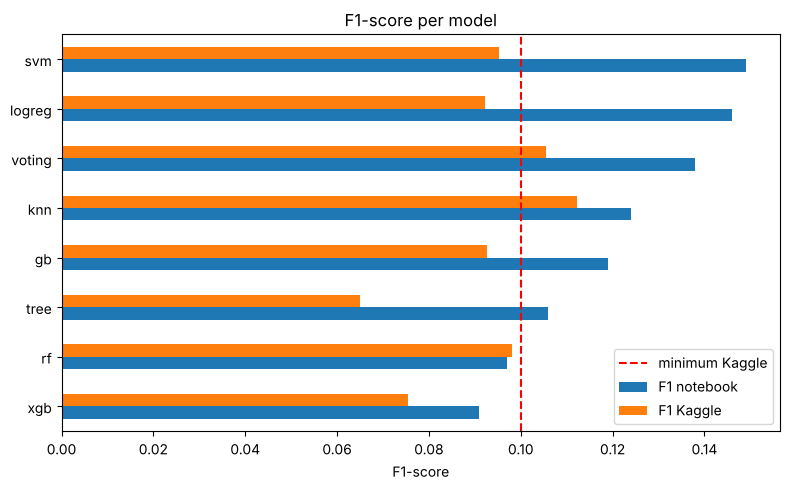

In [32]:
def plot_overview(table):
    """Staafdiagram van de F1-scores in het notebook en op Kaggle."""
    scores = table[["F1 notebook", "F1 Kaggle"]].astype(float)
    scores.sort_values("F1 notebook").plot.barh(figsize=(8, 5))
    plt.axvline(0.1, color="red", linestyle="--", label="minimum Kaggle")
    plt.xlabel("F1-score")
    plt.title("F1-score per model")
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_overview(overview)

## 4.2 Welk model presteert het beste?
**In het notebook** scoren de lineaire modellen het hoogst. De SVM haalt 0,149
(lineaire kernel, C = 1, SMOTE 0,3 en een threshold van 0,33 op de afstand) en
Logistic Regression 0,146 (C = 10, L2, volledig gebalanceerd met SMOTE en een
threshold van 0,81).

**Op Kaggle** ziet de volgorde er anders uit. KNN scoort het hoogst met 0,112
(manhattan, k = 400, SMOTE 0,3 en een threshold van 0,52), gevolgd door ons
eigen ensemble met 0,106 (gewichten [2, 1, 1], SMOTE 0,3 en een threshold van
0,49). Dit zijn de enige twee modellen boven de 0,1. De SVM en Logistic
Regression komen uit op 0,095 en 0,092.

**Waarom verschillen de scores zo?**
1. *De notebook-scores zijn te optimistisch.* We kiezen de threshold op
   dezelfde cross-validation-voorspellingen waarop we de score berekenen.
   Bijna ieder model scoort op Kaggle lager, tot ruim 0,05 lager bij de SVM
   en Logistic Regression.
2. *Het public leaderboard is klein.* Het rekent met ongeveer 4.100
   patiënten, waarvan naar verwachting maar zo'n 60 met een stroke. Een paar
   patiënten meer of minder goed voorspeld verschuift de score al met 0,01 tot
   0,02. De verschillen tussen de modellen op Kaggle vallen grotendeels
   binnen die marge.
3. *Een aantal modellen wijst dezelfde patiënten aan.* In de tabel hieronder
   zien we dat de SVM voor 94% dezelfde patiënten als stroke aanwijst als
   Logistic Regression. Als het public deel ongunstig uitvalt voor die groep
   patiënten, zakken ze dus allebei. KNN, Random Forest en XGBoost kiezen voor
   een groot deel andere patiënten.

In [33]:
def overlap_with(reference, names):
    """Vergelijkt welke patiënten modellen als stroke aanwijzen.

    Geeft per model het aantal voorspelde stroke-patiënten en het percentage
    daarvan dat ook door het referentiemodel als stroke wordt aangewezen.
    """
    ref = pd.read_csv(f"submission_{reference}.csv")["stroke"]
    rows = {}
    for name in names:
        pred = pd.read_csv(f"submission_{name}.csv")["stroke"]
        rows[name] = {"aantal stroke": pred.sum(),
                      f"% ook bij {reference}":
                          round(100 * (pred & ref).sum() / pred.sum())}
    return pd.DataFrame(rows).T


overlap_with("logreg", ["svm", "voting", "tree", "knn", "gb", "rf", "xgb"])

,aantal stroke,% ook bij logreg
svm,467,94
voting,612,87
tree,552,72
knn,485,63
gb,635,61
rf,524,45
xgb,711,36


**Conclusie**
Geen enkel model is duidelijk het beste. KNN wint op Kaggle, maar zit in het
notebook in de middenmoot. De SVM en Logistic Regression zijn het sterkst in
het notebook, maar vallen op Kaggle tegen. Alleen ons eigen ensemble scoort
in beide evaluaties goed, als derde in het notebook (0,138) en als tweede op
Kaggle (0,106). Daarom zien we het ensemble als het beste model overall, met
de gewichten [2, 1, 1] voor Logistic Regression, Random Forest en XGBoost,
SMOTE 0,3 en een threshold van 0,49.

Dat past bij de theorie uit paragraaf 3.8. Door drie verschillende modellen te
middelen, hangt de voorspelling minder af van toeval in één model. De
eindstand op Kaggle wordt berekend op de andere 51% van de testset en kan dus
nog anders uitvallen.

## 4.3 Overwegingen naast de prestaties
Een hoge score is niet het enige wat telt. Zeker in de zorg spelen ook deze
punten mee.

- **Uitlegbaarheid.** Een arts moet kunnen begrijpen waarom een patiënt als
  risicopatiënt wordt aangewezen, en dat ook aan de patiënt kunnen uitleggen.
  Bij Logistic Regression zie je per feature hoeveel het risico stijgt. Een
  beslisboom is te lezen als een stroomschema. Een XGBoost-model of ons eigen
  ensemble is veel meer een black box.
- **Een kans in plaats van ja/nee.** Een arts heeft meer aan "dit is een
  risico van 30%" dan alleen "stroke". Logistic Regression geeft van zichzelf
  een kans. De SVM geeft alleen een afstand tot het hypervlak.
- **Recall tegenover precision.** Een gemiste stroke-patiënt (FN) is in de
  zorg veel erger dan een vals alarm (FP). In de praktijk kiest een
  ziekenhuis misschien liever een lagere threshold met een hogere recall,
  ook als de F1-score daardoor iets daalt. Kaggle beoordeelt op F1, maar de
  arts heeft andere prioriteiten.
- **Snelheid en onderhoud.** Logistic Regression traint in 0,2 seconde, de
  SVM had ruim 30 seconden nodig. KNN traint bijna direct, maar moet bij iedere
  voorspelling alle 33.000 patiënten vergelijken. Ook moet de hele dataset
  met patiëntgegevens bij het model bewaard blijven. Dat is niet handig voor
  de privacy.
- **Betrouwbaarheid.** Als twee modellen bijna even goed scoren, kies je
  liever het eenvoudigste. Dat model is stabieler en de kans is kleiner dat
  het op nieuwe patiënten ineens slechter presteert.
- **Eerlijkheid.** Features als `ever_married` en `work_type` hangen vooral
  samen met leeftijd. Een model mag geen groepen benadelen op basis van
  kenmerken die medisch weinig zeggen.

## 4.4 Advies aan artsen
Wij adviseren artsen om ons **eigen ensemble** te gebruiken. Dat is soft voting
met Logistic Regression, Random Forest en XGBoost, de gewichten [2, 1, 1],
SMOTE 0,3 en een threshold van 0,49. We hebben daar vier redenen voor.
1. Het is het enige model dat in beide evaluaties goed scoort (0,138 in het
   notebook en 0,106 op Kaggle). Het is daarmee het betrouwbaarst op nieuwe
   patiënten.
2. Omdat het drie verschillende modellen combineert, hangt het minder af van
   toeval. Op Kaggle zagen we hoe sterk de scores van losse modellen kunnen
   schommelen.
3. Door soft voting geeft het voor iedere patiënt een kans. De arts ziet een
   risicopercentage en kan zelf een andere grens kiezen, bijvoorbeeld een
   lagere om minder patiënten te missen.
4. Logistic Regression telt dubbel mee. Via de coëfficiënten uit paragraaf
   3.4.4 kan de arts nagaan welke factoren het risico verhogen (leeftijd,
   glucose, hypertensie en hartziekte), ook al is het ensemble als geheel
   minder doorzichtig dan Logistic Regression alleen.

*Waarom niet de andere modellen?* KNN scoorde op Kaggle het hoogst, maar is
traag bij het voorspellen, moet alle patiëntgegevens bewaren en laat niet zien
waarom het iets voorspelt. Ook scoorde het in het notebook maar gemiddeld.
Logistic Regression is het best uit te leggen, maar viel op Kaggle tegen. Als
uitlegbaarheid voor een ziekenhuis het belangrijkst is, blijft het wel een goed
alternatief.

Het model is bedoeld als **hulpmiddel bij screening en niet als diagnose**.
Het wijst patiënten aan die extra aandacht verdienen, maar de arts beslist.
Met een F1 van ongeveer 0,1 maakt het model nog veel fouten. Van de patiënten
die het aanwijst heeft maar een klein deel echt een stroke, en een groot
deel van de stroke-patiënten wordt gemist.

**Beperkingen en vervolgonderzoek**
- De F1-scores in het notebook zijn te optimistisch, want op Kaggle scoren de
  modellen tot ruim 0,05 lager. Een aparte hold-out set, waarop we de
  threshold niet kiezen, zou een eerlijkere schatting geven.
- Het public leaderboard bevat maar ongeveer 60 stroke-patiënten. De
  verschillen tussen de modellen op Kaggle zijn daardoor deels toeval.
- SMOTE maakt kommagetallen in de 0/1-kolommen. Met SMOTENC, een variant voor
  categorische features, gebeurt dat niet. Dat helpt waarschijnlijk vooral de
  boommodellen.
- Een aantal beste hyperparameters ligt op de rand van de grid, zoals k = 400
  bij KNN, max_depth 4 bij de beslisboom, max_depth 2 en learning_rate 0,05
  bij Gradient Boosting en SMOTE 0,3. Een grotere grid kan nog betere modellen
  opleveren.
- Door SMOTE zijn de voorspelde kansen te hoog. Voordat een arts ze als
  risicopercentage gebruikt, moeten ze gekalibreerd worden.
- Voordat het model echt in een ziekenhuis gebruikt wordt, moet het getest
  worden op data van andere ziekenhuizen en patiëntgroepen.

# 5. Bronnen

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://link.springer.com/article/10.1023/A:1010933404324

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and regression trees*. Wadsworth.

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://www.jair.org/index.php/jair/article/view/10302

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://dl.acm.org/doi/epdf/10.1145/2939672.2939785

Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*(3), 273–297. https://link.springer.com/article/10.1007/BF00994018

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232. https://projecteuclid.org/journals/annals-of-statistics/volume-29/issue-5/Greedy-function-approximation-A-gradient-boosting-machine/10.1214/aos/1013203451.full

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer. https://link.springer.com/book/10.1007/978-0-387-84858-7

Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Peduzzi, P., Concato, J., Kemper, E., Holford, T. R., & Feinstein, A. R. (1996). A simulation study of the number of events per variable in logistic regression analysis. *Journal of Clinical Epidemiology, 49*(12), 1373–1379. https://www.jclinepi.com/article/S0895-4356(96)00236-3/abstract

Radhakrishnan, V. M. (2023a). *Ensembling in machine learning* [Slides]. De Haagse Hogeschool.

Radhakrishnan, V. M. (2023b). *Loss, metrics, underfitting & overfitting* [Slides]. De Haagse Hogeschool.

Radhakrishnan, V. M. (2023c). *Niet-lineaire transformaties & kernel* [Slides]. De Haagse Hogeschool.

Radhakrishnan, V. M. (2025). *Gradient descent* [Slides]. De Haagse Hogeschool.